In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Carga de datos

In [3]:
df_casas_entrenamiento = pd.read_csv('https://raw.githubusercontent.com/MartinDido100/ciencia-de-datos/refs/heads/main/primer_parcial/datasets/casas_entrenamiento.csv')
df_casas_entrenamiento.head(5)

,id,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,...,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
0,vz/dYJl3t6dAAhuCMR9pFg==,Propiedad,2020-03-21,9999-12-31,2020-03-21,-34.378947,-58.554400,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,...,NaN,NaN,4.0,3.0,2.0,NaN,NaN,NaN,"Casa en Venta en Primera sección, Tigre U$S 19...",no paga
1,7WuevfRjW78WomnkinRSAA==,Propiedad,2019-05-22,9999-12-31,2019-05-22,-34.432222,-58.573983,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,...,NaN,NaN,3.0,NaN,1.0,120.0,105.0,Mensual,Casa en venta en Tigre con dos dormitorios y j...,no paga
2,zZlOOuCPY//CPsAuwgfICA==,Propiedad,2019-10-13,2019-10-28,2019-10-13,-34.593240,-58.444160,Argentina,Capital Federal,Villa Crespo,...,NaN,NaN,NaN,2.0,2.0,230.0,230.0,NaN,Casa de 3 ambientes en Venta en Villa crespo,no paga
3,dZmdfoiNyUCOgDbRXIuPCg==,Propiedad,2020-01-10,9999-12-31,2020-01-10,-34.520223,-58.738390,Argentina,Bs.As. G.B.A. Zona Norte,José C Paz,...,NaN,NaN,4.0,NaN,1.0,63.0,63.0,Mensual,DUPLEX A ESTRENAR/ 2 DORMITORIOS / Jose C Paz,no paga
4,nt8/Rc6J4m3all/FkfX0gQ==,Propiedad,2019-04-03,2020-04-16,2019-04-03,-37.971410,-57.559851,Argentina,Buenos Aires Costa Atlántica,Mar del Plata,...,NaN,NaN,8.0,6.0,NaN,NaN,NaN,NaN,Inmueble en block en Venta. 8 Amb. 6 Dor,no paga


In [4]:
df_casas_predecir = pd.read_csv('https://raw.githubusercontent.com/MartinDido100/ciencia-de-datos/refs/heads/main/primer_parcial/datasets/casas_predecir.csv')
df_casas_predecir.head(5)

,id,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,...,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
0,YNsMDAiJDbpSUbOHt+rSvQ==,Propiedad,2020-04-04,9999-12-31,2020-04-04,-34.596478,-58.584692,Argentina,Bs.As. G.B.A. Zona Oeste,Tres de Febrero,...,NaN,NaN,4.0,3.0,3.0,NaN,NaN,NaN,Triplex en Venta en Ciudad Jardin,no paga
1,BoKiYfTPcZ8LpdTSuS7PVA==,Propiedad,2019-07-04,9999-12-31,2019-07-04,-34.497770,-58.714840,Argentina,Bs.As. G.B.A. Zona Norte,Malvinas Argentinas,...,NaN,NaN,4.0,NaN,1.0,120.0,120.0,Mensual,Casa - Grand Bourg,no paga
2,sUU+KBSqGEYMNmENHFLomA==,Propiedad,2019-11-29,9999-12-31,2019-11-29,-34.741347,-58.399689,Argentina,Bs.As. G.B.A. Zona Sur,Lomas de Zamora,...,NaN,NaN,4.0,0.0,1.0,NaN,NaN,NaN,"Casa en Venta en Banfield oeste, banfield U$...",no paga
3,4aFQ09OzllVbPl57kB7oCQ==,Propiedad,2019-09-03,9999-12-31,2019-09-03,-34.623179,-58.519398,Argentina,Capital Federal,Versalles,...,NaN,NaN,4.0,NaN,2.0,230.0,126.0,Mensual,Casa 4 ambientes Reciclada a nueva en Impecabl...,no paga
4,bczZnJ0pADQI2XNR4ivWvg==,Propiedad,2019-04-30,9999-12-31,2019-04-30,-37.977329,-57.557187,Argentina,Buenos Aires Costa Atlántica,Mar del Plata,...,NaN,NaN,3.0,2.0,1.0,150.0,100.0,NaN,Chalet en Venta. 3 Amb. 2 Dor. 150 M2. 100 M2 Cub,no paga


`id` va a ser el índice, pero no lo ponemos acá: lo hace la función `id_como_indice` al principio del pipeline. Hasta ese punto `id` sigue siendo una columna, y las celdas de revisión y limpieza lo tratan como tal.

¿Por qué índice y no columna? El id no es una característica de la casa. Es un código al azar que no dice nada sobre si paga comisión. Si queda como columna, es fácil que termine entrando al modelo sin querer, por ejemplo al hacer df.drop(columns='paga_comision') para armar X. Tiene un valor distinto por fila, así que solo aporta ruido. Y con one-hot encoding generaría una columna nueva por casa.
Permite controlar los errores que se mencionan en el enunciado y verificar que los ids del entregable pertenezcan a casas_predecir.csv y no a los de entrenamiento.

## Trampas de estructura (1/4): columnas de cada archivo

**Por qué:** el modelo se entrena con las columnas de `casas_entrenamiento` y después se aplica a `casas_predecir`. Si un archivo tiene una columna que el otro no, o la misma columna con otro tipo de dato, el modelo falla al predecir o usa información que no va a estar disponible.

**Qué hace:** arma una tabla con todas las columnas de los dos archivos, una al lado de la otra, con el tipo de dato en cada uno y si coinciden. Debajo lista las columnas que están en un solo archivo.

In [5]:
# Comparación de columnas entre los dos archivos

tr = df_casas_entrenamiento if 'id' in df_casas_entrenamiento.columns else df_casas_entrenamiento.reset_index()
pr = df_casas_predecir if 'id' in df_casas_predecir.columns else df_casas_predecir.reset_index()

# Tabla con todas las columnas de ambos datasets, una al lado de la otra.
# Si una columna falta en un archivo, su tipo aparece como NaN en esa fila.
comparacion_columnas = pd.DataFrame({
    'casas_entrenamiento': tr.dtypes,
    'casas_predecir': pr.dtypes,
})
comparacion_columnas['tipos_iguales'] = comparacion_columnas['casas_entrenamiento'] == comparacion_columnas['casas_predecir']
print("Cantidad de columnas -> entrenamiento:", tr.shape[1], "| predecir:", pr.shape[1])
display(comparacion_columnas)

# Columnas presentes en un archivo y no en el otro
cols_tr, cols_pr = set(tr.columns), set(pr.columns)
print("Solo en entrenamiento:", sorted(cols_tr - cols_pr))
print("Solo en predecir:     ", sorted(cols_pr - cols_tr))

Cantidad de columnas -> entrenamiento: 21 | predecir: 21


,casas_entrenamiento,casas_predecir,tipos_iguales
id,str,str,True
ad_type,str,str,True
start_date,str,str,True
end_date,str,str,True
created_on,str,str,True
lat,float64,float64,True
lon,float64,float64,True
l1,str,str,True
l2,str,str,True
l3,str,str,True


Solo en entrenamiento: []
Solo en predecir:      []


## Trampas de estructura (2/4): ids duplicados y compartidos

**Por qué:** `id` va a ser el índice y es lo único que se entrega en `casas_entrega.csv`. Si un id se repite dentro de un archivo, una misma predicción quedaría asociada a dos casas. Si un id aparece en los dos archivos, se podría terminar entregando un id de entrenamiento.

**Qué hace:** cuenta filas, ids únicos e ids repetidos en cada archivo, y calcula cuántos ids comparten casas_entrenamiento y casas_predecir. Al final, tres `assert` frenan el notebook si alguna de estas condiciones no se cumple, para no seguir trabajando sobre una base rota.

In [6]:
tr = df_casas_entrenamiento if 'id' in df_casas_entrenamiento.columns else df_casas_entrenamiento.reset_index()
pr = df_casas_predecir if 'id' in df_casas_predecir.columns else df_casas_predecir.reset_index()

datasets = {'casas_entrenamiento': tr, 'casas_predecir': pr}
for nombre, df in datasets.items():
    print(f"[{nombre}] filas: {len(df)} | ids únicos: {df['id'].nunique()} | ids duplicados: {df['id'].duplicated().sum()}")
ids_compartidos = set(tr['id']) & set(pr['id'])
print("Ids compartidos entre entrenamiento y predecir:", len(ids_compartidos))

# Verificaciones que el resto del notebook da por hechas
assert tr['id'].is_unique, "Hay ids repetidos en entrenamiento"
assert pr['id'].is_unique, "Hay ids repetidos en predecir"
assert len(ids_compartidos) == 0, "Hay ids compartidos entre entrenamiento y predecir"

[casas_entrenamiento] filas: 61577 | ids únicos: 61577 | ids duplicados: 0
[casas_predecir] filas: 41054 | ids únicos: 41054 | ids duplicados: 0
Ids compartidos entre entrenamiento y predecir: 0


## Trampas de estructura (3/4): filas duplicadas

**Por qué:** una misma propiedad puede estar publicada varias veces con distinto id (avisos re-publicados). Eso trae tres problemas:
- Si una copia queda en train y otra en test, el modelo "reconoce" la casa en vez de predecirla y la ganancia estimada sale optimista.
- Si las copias tienen etiquetas distintas, hay ruido en la variable objetivo.
- Si una casa de predecir es idéntica a una de entrenamiento, su etiqueta ya se conoce.

**Qué hace:** en cada archivo cuenta los duplicados exactos (todas las columnas) y los duplicados ignorando `id` y `paga_comision` (en predecir esa columna es relleno). En entrenamiento cuenta cuántos grupos de casas idénticas tienen etiquetas contradictorias. Por último, cruza los dos archivos para contar cuántas filas de predecir son idénticas a alguna de entrenamiento.

In [7]:
# Filas duplicadas
tr = df_casas_entrenamiento if 'id' in df_casas_entrenamiento.columns else df_casas_entrenamiento.reset_index()
pr = df_casas_predecir if 'id' in df_casas_predecir.columns else df_casas_predecir.reset_index()

# - exactas (todas las columnas, incluido id)
# - "misma propiedad con otro id": se ignoran id y paga_comision
features = [c for c in tr.columns if c not in ('id', 'paga_comision')]
for nombre, df in {'casas_entrenamiento': tr, 'casas_predecir': pr}.items():
    print(f"[{nombre}] duplicados exactos: {df.duplicated().sum()} | "
          f"duplicados ignorando id: {df.duplicated(subset=features).sum()}")

# En entrenamiento: ¿hay duplicados con etiquetas distintas? (misma casa, una 'paga' y otra 'no paga')
etiquetas_por_casa = tr.groupby(features, dropna=False)['paga_comision'].nunique()
print("\nGrupos de duplicados en entrenamiento con etiqueta contradictoria:", (etiquetas_por_casa > 1).sum())

# Entre archivos: filas de predecir idénticas a alguna de entrenamiento (sin contar id ni target)
cruce = pr[features].merge(tr[features].drop_duplicates(), how='inner', on=features)
print("Filas de predecir idénticas a una de entrenamiento:", len(cruce))

[casas_entrenamiento] duplicados exactos: 0 | duplicados ignorando id: 867
[casas_predecir] duplicados exactos: 0 | duplicados ignorando id: 425

Grupos de duplicados en entrenamiento con etiqueta contradictoria: 16
Filas de predecir idénticas a una de entrenamiento: 907


+ [casas_entrenamiento] duplicados exactos: 0 | duplicados ignorando id: 867    -> Hay que eliminar los duplicados del set de entrenamiento porque producen overfitting.

+ [casas_predecir] duplicados exactos: 0 | duplicados ignorando id: 425         -> No hace falta eliminarlos ya que pueden ser duplicados reales.

+ Grupos de duplicados en __entrenamiento__ con etiqueta contradictoria: 16         -> Los 16 grupos (33 filas en total) hay que eliminarlos ya que presentan contradicción para el modelo.

+ Filas de predecir idénticas a una de entrenamiento: 907                       -> **Eliminamos las filas del set de entrenamiento ya que el dataset de producción debe predecirse completo. Así también evitamos data leakage**.

## Trampas de estructura (4/4): casas de más de US$ 300.000 marcadas como `no paga`

**Por qué:** según el enunciado, una casa paga comisión cuando su precio de venta supera los **US$ 300.000**. En el entrenamiento hay casas con precio en el título por encima de ese valor que figuran como `no paga`. Esas etiquetas contradicen la regla del enunciado, así que se corrigen a `paga` antes de la limpieza de duplicados, del análisis exploratorio y del pipeline.

**Qué hace:** extrae el precio en dólares del título (sin contar alquileres, cuyo precio no es de venta) y pasa a `paga` las casas con precio > US$ 300.000 que figuran como `no paga`. Solo se pueden corregir las casas que traen el precio en el título. `casas_predecir` no se toca.

Las funciones `normalizar_texto` y `extraer_precio_usd` se definen acá porque las usa este paso; el pipeline las reutiliza más adelante.


In [8]:
import re
import unicodedata

# Marcas de moneda en dólares que aceptamos en el título. '$' solo NO: es ambiguo (pesos o dólares)
PATRON_PRECIO = re.compile(r'(?:u\$s|u\$d|usd|us\$|u\$)\s*(\d[\d\.,]*)')

def normalizar_texto(texto):
    # Minúsculas y sin tildes, para que 'Dúplex' y 'DUPLEX' se detecten igual
    texto = unicodedata.normalize('NFKD', str(texto).lower())
    return ''.join(c for c in texto if not unicodedata.combining(c))

def extraer_precio_usd(texto):
    # Busca 'U$S 190.000', 'USD 580.000', 'U$425.000', etc. Devuelve el número, o NaN si no hay precio
    m = PATRON_PRECIO.search(texto)
    if not m:
        return np.nan
    numero = re.sub(r'[\.,]\d{1,2}$', '', m.group(1).rstrip('.,'))  # saca decimales tipo ',00'
    numero = re.sub(r'[\.,]', '', numero)                            # saca separadores de miles
    if not numero:
        return np.nan
    valor = float(numero)
    # Fuera de un rango razonable es un número cortado ('U$D 550.') o mal escrito: no se usa
    return valor if 10_000 <= valor <= 50_000_000 else np.nan


titulo_tr = df_casas_entrenamiento['title'].fillna('').map(normalizar_texto)
es_alquiler_tr = titulo_tr.str.contains(r'\b(?:alquiler|alquilo|temporada)\b', regex=True)
precio_titulo_tr = titulo_tr.map(extraer_precio_usd).where(~es_alquiler_tr)

a_reetiquetar = (precio_titulo_tr > 300_000) & (df_casas_entrenamiento['paga_comision'] == 'no paga')
tasa_antes = (df_casas_entrenamiento['paga_comision'] == 'paga').mean()

df_casas_entrenamiento = df_casas_entrenamiento.copy()
df_casas_entrenamiento.loc[a_reetiquetar, 'paga_comision'] = 'paga'
tasa_despues = (df_casas_entrenamiento['paga_comision'] == 'paga').mean()

print("Casas con precio > US$ 300.000 marcadas como 'no paga':", a_reetiquetar.sum())
print(f"Tasa de paga: {tasa_antes:.4f} -> {tasa_despues:.4f}")

assert not ((precio_titulo_tr > 300_000) & (df_casas_entrenamiento['paga_comision'] == 'no paga')).any()


Casas con precio > US$ 300.000 marcadas como 'no paga': 1856
Tasa de paga: 0.1110 -> 0.1412


## Limpieza de duplicados (1/3): casas con etiqueta contradictoria (16 grupos, 33 filas)

**Por qué:** hay propiedades idénticas en todas sus columnas (salvo `id`) que en una fila figuran como `paga` y en otra como `no paga`. Con los mismos datos de entrada, el modelo recibe dos respuestas opuestas: es ruido que no puede aprender. Como no hay forma de saber cuál etiqueta es la correcta, se eliminan **todas** las filas de esos grupos, sin elegir una. Este paso va antes de quitar los duplicados: si se deduplicara primero, cada grupo quedaría en una sola fila con una etiqueta elegida al azar y la contradicción ya no se vería.

**Qué hace:** calcula una "huella" de cada fila a partir de todas las columnas menos `id` y `paga_comision` (filas idénticas tienen la misma huella). Cuenta cuántas etiquetas distintas tiene cada huella y elimina del entrenamiento las filas cuya huella tiene más de una.

In [9]:
# Columnas que describen la casa: todas menos id y el target
# (funciona tanto si id es columna como si ya es el índice)
features = [c for c in df_casas_entrenamiento.columns if c not in ('id', 'paga_comision')]

# Huella de cada fila: filas idénticas en 'features' tienen el mismo número (los NaN también se comparan bien)
huella_tr = pd.util.hash_pandas_object(df_casas_entrenamiento[features], index=False)

# Para cada fila, cuántas etiquetas distintas tiene su grupo de casas idénticas
etiquetas_en_grupo = df_casas_entrenamiento.groupby(huella_tr)['paga_comision'].transform('nunique')
contradictorias = etiquetas_en_grupo > 1

filas_antes = len(df_casas_entrenamiento)
print("Grupos con etiqueta contradictoria:", huella_tr[contradictorias].nunique())
print("Filas a eliminar (todas las de esos grupos):", contradictorias.sum())

df_casas_entrenamiento = df_casas_entrenamiento[~contradictorias]
print(f"Entrenamiento: {filas_antes} -> {len(df_casas_entrenamiento)} filas")

# Verificación: ya no queda ninguna casa con dos etiquetas distintas
huella_tr = pd.util.hash_pandas_object(df_casas_entrenamiento[features], index=False)
assert (df_casas_entrenamiento.groupby(huella_tr)['paga_comision'].nunique() == 1).all()

Grupos con etiqueta contradictoria: 16
Filas a eliminar (todas las de esos grupos): 33
Entrenamiento: 61577 -> 61544 filas


## Limpieza de duplicados (2/3): duplicados dentro del entrenamiento

**Por qué:** una misma casa publicada varias veces con distinto `id` pesa doble en el entrenamiento, y al separar train/test una copia puede quedar de cada lado. En ese caso el modelo "reconoce" la casa en vez de predecirla, sobreajusta y la ganancia estimada en test sale más alta de lo que va a ser con casas nuevas. En `casas_predecir` no se eliminan: hay que entregar una predicción para cada `id`.

**Qué hace:** elimina las filas del entrenamiento que son idénticas a otra en todas las columnas menos `id` (la etiqueta ya coincide, porque las contradictorias se quitaron en el paso anterior). Conserva la primera aparición de cada casa.

In [10]:
# Duplicados de la misma casa con distinto id (se ignora id; la etiqueta ya es consistente)
features = [c for c in df_casas_entrenamiento.columns if c not in ('id', 'paga_comision')]

filas_antes = len(df_casas_entrenamiento)
print("Duplicados a eliminar:", df_casas_entrenamiento.duplicated(subset=features).sum())

# keep='first': de cada grupo de casas idénticas queda la primera fila
df_casas_entrenamiento = df_casas_entrenamiento.drop_duplicates(subset=features, keep='first')
print(f"Entrenamiento: {filas_antes} -> {len(df_casas_entrenamiento)} filas")

# Verificación: no quedan casas repetidas en el entrenamiento
assert not df_casas_entrenamiento.duplicated(subset=features).any()

Duplicados a eliminar: 850
Entrenamiento: 61544 -> 60694 filas


## Limpieza de duplicados (3/3): casas de entrenamiento que también están en predecir

**Por qué:** hay casas de `casas_predecir` idénticas a casas del entrenamiento. `casas_predecir` es el dataset de producción y se predice completo, así que de ahí no se puede sacar nada; las coincidencias se quitan del entrenamiento. Así los dos conjuntos quedan disjuntos: el modelo se entrena y se valida solo con casas que no va a tener que predecir, y su rendimiento estimado refleja lo que va a pasar con casas nuevas, no con casas que ya vio.

**Qué hace:** calcula la huella (todas las columnas menos `id` y `paga_comision`) de cada fila de los dos archivos y elimina del entrenamiento las filas cuya huella aparece en `casas_predecir`. `casas_predecir` no se modifica.

In [11]:
# Casas del entrenamiento idénticas a alguna de predecir (sin contar id ni target)
features = [c for c in df_casas_entrenamiento.columns if c not in ('id', 'paga_comision')]

huella_tr = pd.util.hash_pandas_object(df_casas_entrenamiento[features], index=False)
huella_pr = pd.util.hash_pandas_object(df_casas_predecir[features], index=False)
en_predecir = huella_tr.isin(huella_pr)

filas_antes, filas_predecir = len(df_casas_entrenamiento), len(df_casas_predecir)
print("Filas de entrenamiento que también están en predecir:", en_predecir.sum())
print("Filas de predecir afectadas (se mantienen):", huella_pr.isin(huella_tr).sum())

df_casas_entrenamiento = df_casas_entrenamiento[~en_predecir]
print(f"Entrenamiento: {filas_antes} -> {len(df_casas_entrenamiento)} filas")

# Verificaciones: los conjuntos quedaron disjuntos y predecir no perdió filas
huella_tr = pd.util.hash_pandas_object(df_casas_entrenamiento[features], index=False)
assert not huella_tr.isin(huella_pr).any()
assert len(df_casas_predecir) == filas_predecir

Filas de entrenamiento que también están en predecir: 708
Filas de predecir afectadas (se mantienen): 902
Entrenamiento: 60694 -> 59986 filas


# Análisis exploratorio
Sobre los datos limpios, analizamos lo que va a entrar al modelo.

## Variable target: `paga_comision`

paga_comision
no paga    51495
paga        8491
Name: count, dtype: int64
paga_comision
no paga    85.85
paga       14.15
Name: proportion, dtype: float64


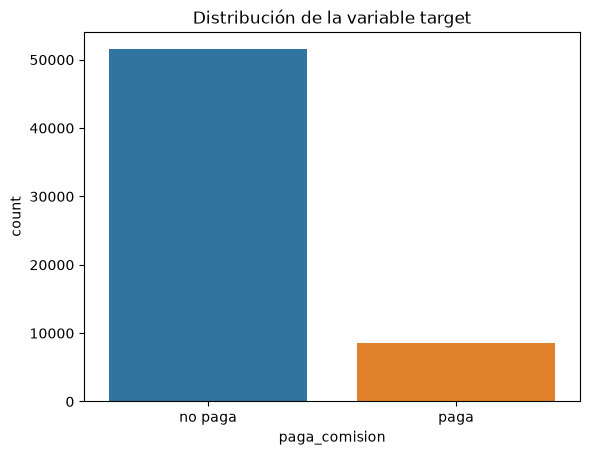

In [12]:
print( df_casas_entrenamiento.paga_comision.value_counts() )
print( (df_casas_entrenamiento.paga_comision.value_counts(normalize=True) * 100).round(2) )
sns.countplot(x='paga_comision', data=df_casas_entrenamiento, hue='paga_comision', legend=False)
plt.title('Distribución de la variable target')
plt.show()

El dataset está **desbalanceado** (~85% `no paga` vs ~14% `paga`). Un modelo que siempre diga `no paga` tendría un accuracy de casi 85% y ganancia nula, por eso hay que evaluar con la **función de ganancia** del enunciado y no solo con accuracy.

Para los gráficos trabajamos sobre una copia (`df_eda`) con el target en formato numérico (1 = paga), así el promedio de `target` por grupo es directamente la **tasa de pago de comisión**.

In [13]:
# Copia para el EDA: las celdas de abajo agregan columnas (fechas, dias_publicado, etc.)
# y no queremos que lleguen al dataset que entra al pipeline
df_eda = df_casas_entrenamiento.copy()
df_eda['target'] = (df_eda.paga_comision == 'paga').astype(int)

tasa_global = df_eda.target.mean()
print(f"Tasa global de pago de comisión: {tasa_global:.2%}")

Tasa global de pago de comisión: 14.15%


## ¿Los nulos dicen algo sobre el target?
Si el porcentaje de nulos de una columna es distinto entre `paga` y `no paga`, el hecho de que falte el dato es información útil (se puede crear una feature indicadora de nulo en vez de solo imputar).

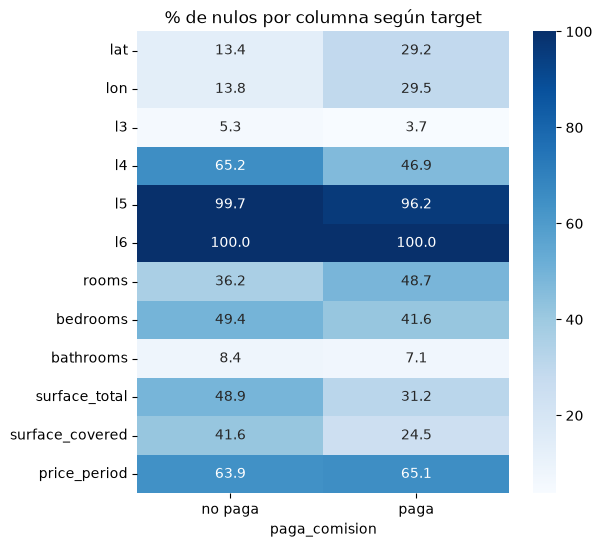

In [14]:
nulos_por_target = df_eda.drop(columns=['target']).isnull().groupby(df_eda.paga_comision).mean().T * 100
nulos_por_target = nulos_por_target[nulos_por_target.sum(axis=1) > 0]

plt.figure(figsize=(6,6))
sns.heatmap(nulos_por_target, annot=True, fmt='.1f', cmap='Blues')
plt.title('% de nulos por columna según target')
plt.show()

## Variables numéricas
Hay valores imposibles: superficies negativas o en 0, `bedrooms` negativos o de hasta 37, superficies de 200.000 m² y casas con más superficie cubierta que total. Graficamos con escala logarítmica y recortando al percentil 99 para poder ver la forma real de las distribuciones.

In [15]:
numericas = ['rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered']

print("Superficies <= 0:", (df_eda[['surface_total','surface_covered']] <= 0).sum().to_dict())
print("surface_covered > surface_total:", (df_eda.surface_covered > df_eda.surface_total).sum())
print("Percentil 99:")
print(df_eda[numericas].quantile(0.99))

Superficies <= 0: {'surface_total': 39, 'surface_covered': 1}
surface_covered > surface_total: 1108
Percentil 99:
rooms                10.00
bedrooms              6.00
bathrooms             6.00
surface_total      3403.04
surface_covered     748.74
Name: 0.99, dtype: float64


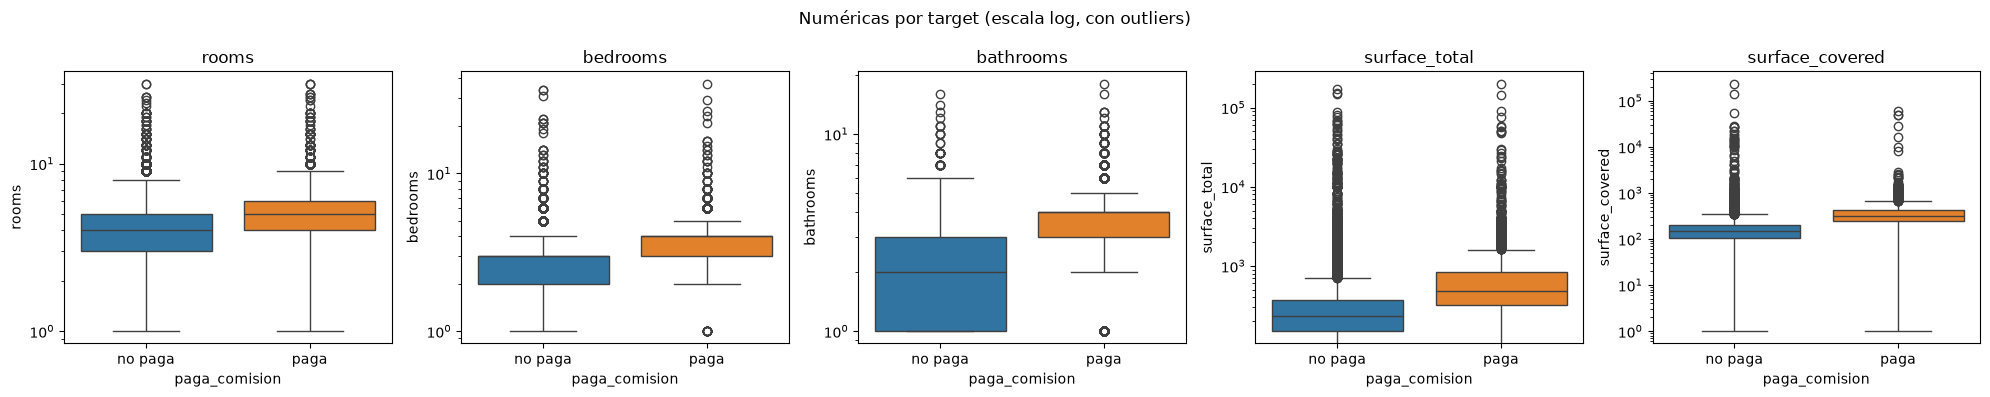

In [16]:
fig, axes = plt.subplots(1, len(numericas), figsize=(20,4))
for ax, col in zip(axes, numericas):
    sns.boxplot(x='paga_comision', y=col, data=df_eda, ax=ax, hue='paga_comision', legend=False)
    ax.set_yscale('log')
    ax.set_title(col)
plt.suptitle('Numéricas por target (escala log, con outliers)')
plt.tight_layout()
plt.show()

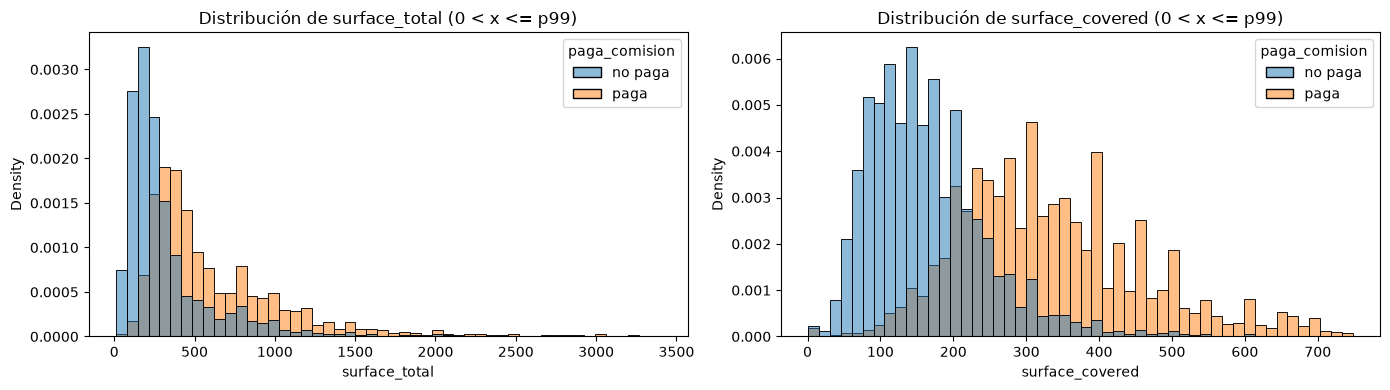

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14,4))
for ax, col in zip(axes, ['surface_total', 'surface_covered']):
    p99 = df_eda[col].quantile(0.99)
    datos = df_eda[(df_eda[col] > 0) & (df_eda[col] <= p99)]
    sns.histplot(data=datos, x=col, hue='paga_comision', bins=50, stat='density', common_norm=False, ax=ax)
    ax.set_title(f'Distribución de {col} (0 < x <= p99)')
plt.tight_layout()
plt.show()

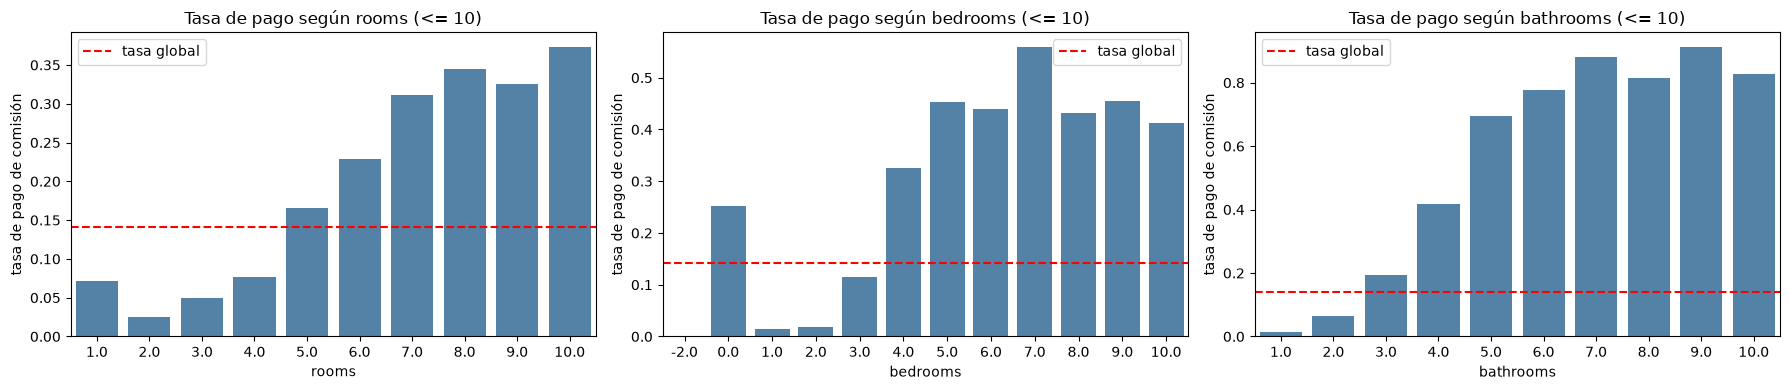

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18,4))
for ax, col in zip(axes, ['rooms', 'bedrooms', 'bathrooms']):
    datos = df_eda[df_eda[col] <= 10]
    sns.barplot(x=col, y='target', data=datos, ax=ax, color='steelblue', errorbar=None)
    ax.axhline(tasa_global, color='red', linestyle='--', label='tasa global')
    ax.set_ylabel('tasa de pago de comisión')
    ax.set_title(f'Tasa de pago según {col} (<= 10)')
    ax.legend()
plt.tight_layout()
plt.show()

## Correlación entre numéricas y target

Antes de modelar queremos saber qué variables numéricas se mueven junto con el target y cuáles son redundantes entre sí. Usamos **Spearman** en lugar de Pearson porque mide relaciones monótonas por ranking, así los outliers e imposibles que vimos arriba (superficies de 200.000 m², `bedrooms` de 37) no distorsionan el resultado.

Incluimos `lat` y `lon` para ver si la ubicación por sí sola tiene relación lineal con el pago de comisión. Una correlación alta entre dos features (por ejemplo `rooms` y `bedrooms`) indica que aportan casi la misma información; una correlación baja con el target no descarta la variable, porque un árbol puede aprovechar relaciones no monótonas.

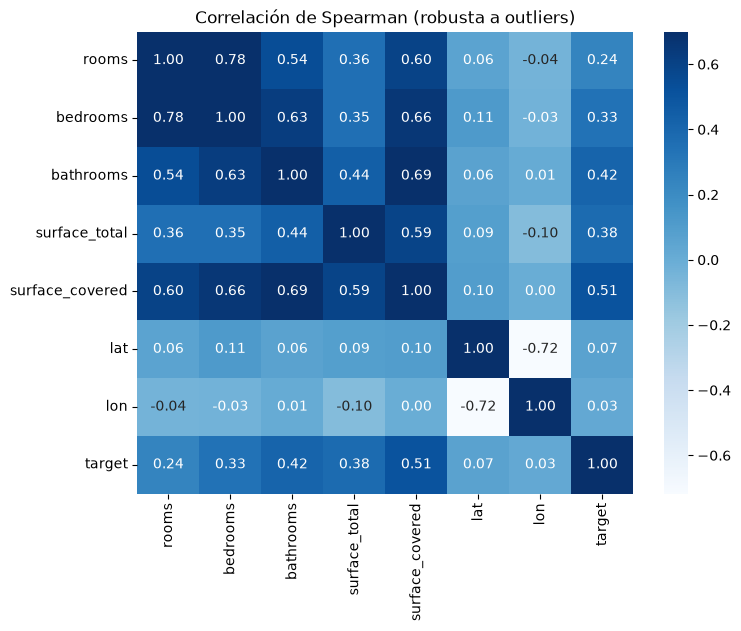

In [19]:
plt.figure(figsize=(8,6))
sns.heatmap(df_eda[numericas + ['lat', 'lon', 'target']].corr(method='spearman'), annot=True, fmt='.2f', cmap='Blues', vmax=.7)
plt.title('Correlación de Spearman (robusta a outliers)')
plt.show()

## Ubicación: país (`l1`) y provincia/región (`l2`)
`l1` (3 países) y `l2` (38 regiones) tienen pocas categorías, así que se pueden usar con one-hot encoding. `l3` (ciudad, 559 valores) tiene alta cardinalidad y en el pipeline se usa con target encoding. `l4` y `l5` tienen muchos nulos (más de la mitad en `l4` y casi el 100% en `l5`) y quedan fuera del modelo.

l1      3
l2     38
l3    559
l4    677
l5     17
dtype: int64


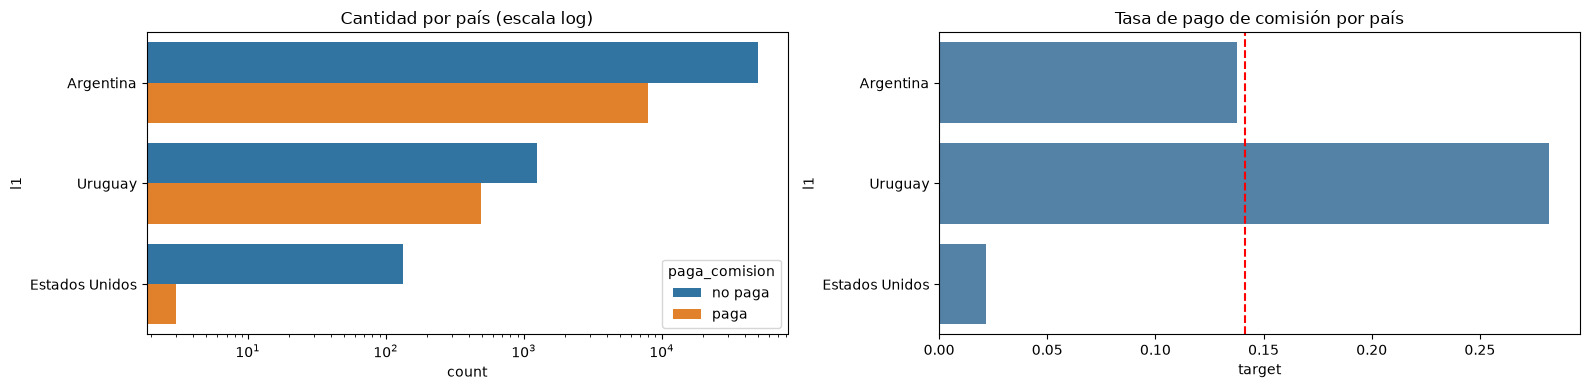

In [20]:
print(df_eda[['l1', 'l2', 'l3', 'l4', 'l5']].nunique())

fig, axes = plt.subplots(1, 2, figsize=(16,4))
sns.countplot(y='l1', data=df_eda, hue='paga_comision', ax=axes[0])
axes[0].set_xscale('log')
axes[0].set_title('Cantidad por país (escala log)')
sns.barplot(y='l1', x='target', data=df_eda, ax=axes[1], color='steelblue', errorbar=None)
axes[1].axvline(tasa_global, color='red', linestyle='--')
axes[1].set_title('Tasa de pago de comisión por país')
plt.tight_layout()
plt.show()

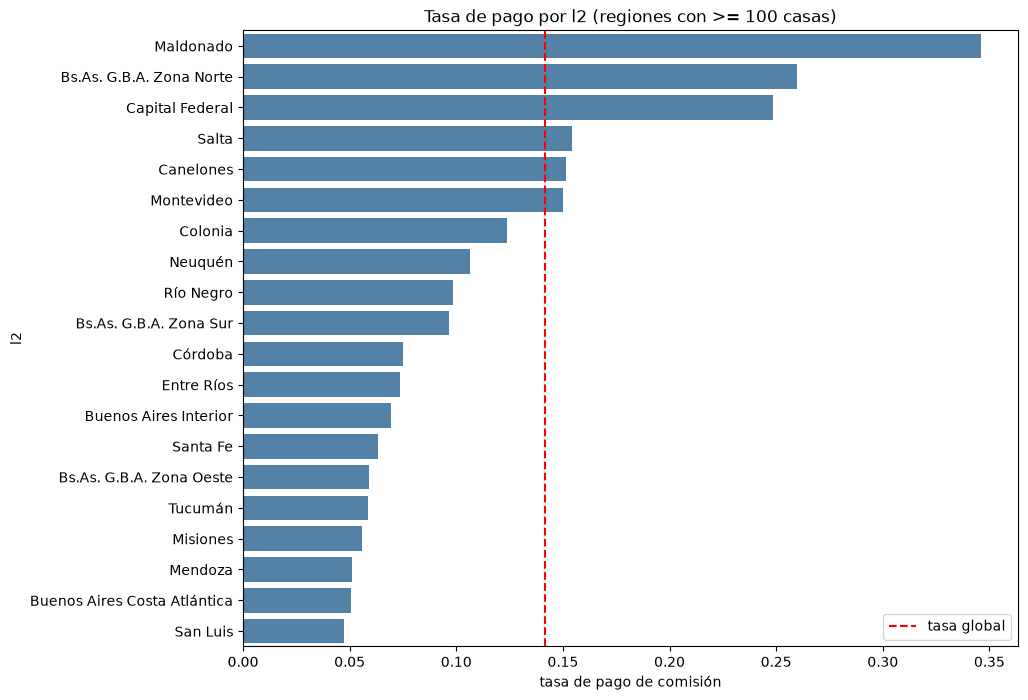

In [21]:
resumen_l2 = df_eda.groupby('l2').target.agg(cantidad='size', tasa='mean')
resumen_l2 = resumen_l2[resumen_l2.cantidad >= 100].sort_values('tasa', ascending=False)

plt.figure(figsize=(10,8))
sns.barplot(y=resumen_l2.index, x=resumen_l2.tasa, color='steelblue')
plt.axvline(tasa_global, color='red', linestyle='--', label='tasa global')
plt.xlabel('tasa de pago de comisión')
plt.title('Tasa de pago por l2 (regiones con >= 100 casas)')
plt.legend()
plt.show()

## Coordenadas (`lat`, `lon`)
El heatmap anterior mostró una correlación casi nula entre las coordenadas y el target. Eso no significa que la ubicación no importe: el pago de comisión no crece hacia el norte ni hacia el este, sino que se concentra en zonas puntuales, y ese patrón no lo captura una correlación. Por eso lo miramos en un mapa.

Antes de graficar hay que filtrar coordenadas inválidas (lat = 85, lon = -180, puntos fuera de Argentina y Uruguay). Ordenamos por `target` para que las casas que pagan se dibujen arriba y no queden tapadas; esto hace que los puntos naranjas se vean más de lo que pesan en proporción.

**Qué se ve:** las casas se agrupan en las ciudades y no se reparten de forma uniforme. Los puntos que pagan aparecen sobre todo en el AMBA, en la costa de Maldonado (extremo este) y en Bariloche. En el resto del país predominan las que no pagan.

Coordenadas fuera de rango (sin contar nulos): 139


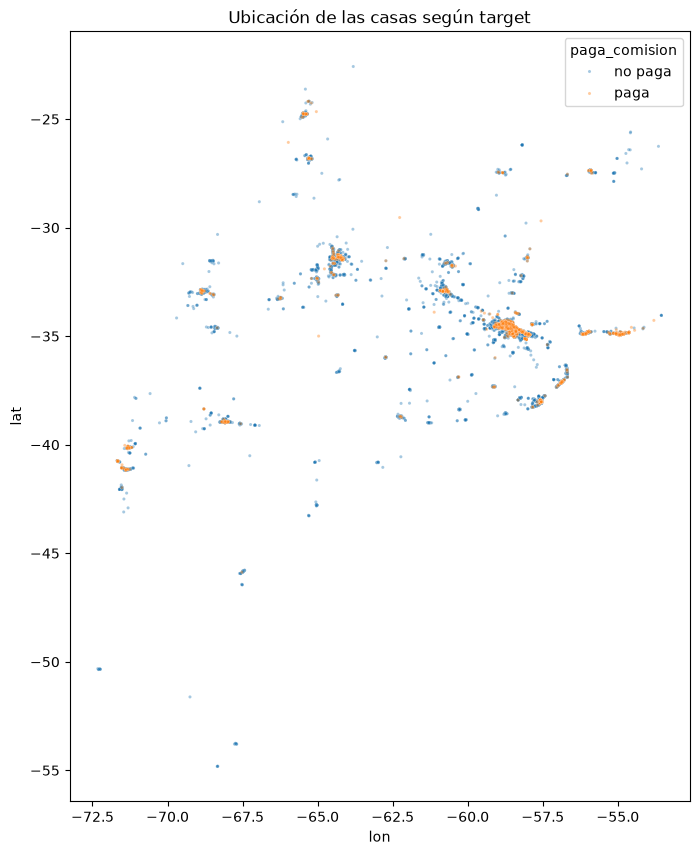

In [22]:
coord_validas = df_eda.lat.between(-56, -21) & df_eda.lon.between(-74, -52)
print("Coordenadas fuera de rango (sin contar nulos):", (~coord_validas & df_eda.lat.notna() & df_eda.lon.notna()).sum())

datos = df_eda[coord_validas].sort_values('target')  # 'paga' se dibuja arriba
plt.figure(figsize=(8,10))
sns.scatterplot(x='lon', y='lat', hue='paga_comision', data=datos, s=5, alpha=0.4)
plt.title('Ubicación de las casas según target')
plt.show()

En el mapa general el AMBA queda como una sola mancha, porque ahí está la mayor parte de las casas. Hacemos zoom para ver si dentro de la región el target también cambia por zona.

**Qué se ve:** las casas que pagan se concentran en el corredor norte sobre el río (Zona Norte y el norte de Capital Federal) y en algunos focos aislados del sur. La Zona Oeste es casi toda `no paga`. Es decir, la tasa cambia por barrio, a una escala más chica que la provincia.

Esta información ya la recogen `l2` (región) y `l3` (ciudad, con target encoding), que además no tienen coordenadas inválidas. Por eso `lat` y `lon` no entran crudas al modelo.

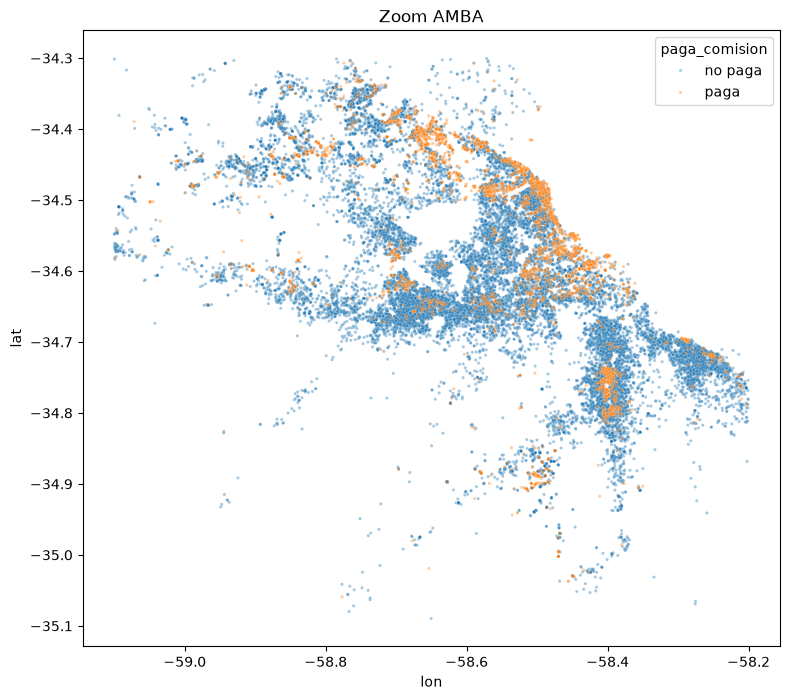

In [23]:
amba = df_eda[df_eda.lat.between(-35.1, -34.3) & df_eda.lon.between(-59.1, -58.2)].sort_values('target')
plt.figure(figsize=(9,8))
sns.scatterplot(x='lon', y='lat', hue='paga_comision', data=amba, s=5, alpha=0.4)
plt.title('Zoom AMBA')
plt.show()

## `price_period` y fechas
`price_period` solo toma `Mensual` o nulo, así que funciona como una variable binaria. De las fechas extraemos información de baja dimensionalidad: mes de publicación, duración del aviso y si sigue activo (`end_date` = 9999-12-31).

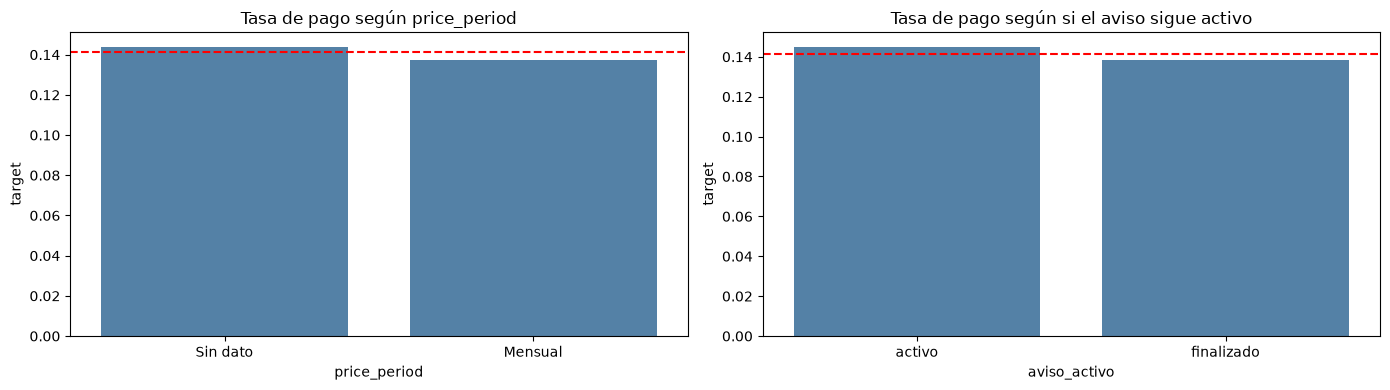

In [24]:
df_eda['price_period'] = df_eda.price_period.fillna('Sin dato')
df_eda['created_on'] = pd.to_datetime(df_eda.created_on)
df_eda['start_date'] = pd.to_datetime(df_eda.start_date)
df_eda['aviso_activo'] = (df_eda.end_date == '9999-12-31').map({True: 'activo', False: 'finalizado'})
df_eda['mes_publicacion'] = df_eda.created_on.dt.to_period('M').astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14,4))
sns.barplot(x='price_period', y='target', data=df_eda, ax=axes[0], color='steelblue', errorbar=None)
axes[0].axhline(tasa_global, color='red', linestyle='--')
axes[0].set_title('Tasa de pago según price_period')
sns.barplot(x='aviso_activo', y='target', data=df_eda, ax=axes[1], color='steelblue', errorbar=None)
axes[1].axhline(tasa_global, color='red', linestyle='--')
axes[1].set_title('Tasa de pago según si el aviso sigue activo')
plt.tight_layout()
plt.show()

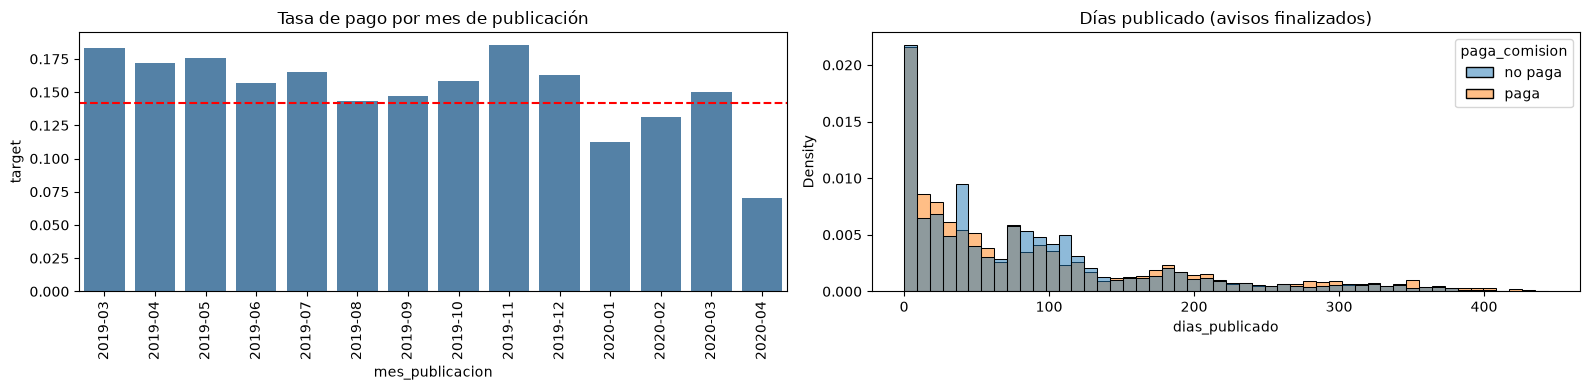

In [25]:
fin = pd.to_datetime(df_eda.end_date.where(df_eda.end_date != '9999-12-31'))
df_eda['dias_publicado'] = (fin - df_eda.start_date).dt.days

fig, axes = plt.subplots(1, 2, figsize=(16,4))
sns.barplot(x='mes_publicacion', y='target', data=df_eda.sort_values('mes_publicacion'), ax=axes[0], color='steelblue', errorbar=None)
axes[0].axhline(tasa_global, color='red', linestyle='--')
axes[0].tick_params(axis='x', rotation=90)
axes[0].set_title('Tasa de pago por mes de publicación')
sns.histplot(data=df_eda, x='dias_publicado', hue='paga_comision', bins=50, stat='density', common_norm=False, ax=axes[1])
axes[1].set_title('Días publicado (avisos finalizados)')
plt.tight_layout()
plt.show()

## Conclusiones del análisis exploratorio
Números calculados sobre el entrenamiento ya limpio (59.986 casas):

1. **Target desbalanceado** (~14% paga): evaluar con la función de ganancia, no con accuracy.
2. **Columnas sin información**: `l6` (100% nula), `ad_type` (un solo valor) y `created_on` (idéntica a `start_date`). Se eliminan.
3. **Tamaño de la casa** (`rooms`, `bedrooms`, `bathrooms`, superficies) es lo que más separa las clases: las que pagan son más grandes (mediana de superficie cubierta 320 m² contra 150 m²). Las numéricas con mayor correlación con el target son `surface_covered` (0,51) y `bathrooms` (0,42). La tasa de pago pasa del 1% con 1 baño al 69% con 5.
4. **Datos inválidos**: superficies negativas o en 0, `surface_covered > surface_total` (1.108 casas), `bedrooms` negativos o extremos y superficies de hasta 200.000 m². En el pipeline se pasan a NaN (no se borran filas, porque en predecir hay que predecir todas) y la superficie cubierta se recorta al percentil 99,9.
5. **Los nulos son informativos**: las superficies faltan más en las que no pagan (48,9% contra 31,2% en `surface_total`) y `rooms` falta más en las que pagan (48,7% contra 36,2%). Por eso en el pipeline se crean indicadores de nulo antes de imputar.
6. **Ubicación**: las tasas por región son muy distintas. Maldonado (35%), Zona Norte (26%) y Capital Federal (25%) están muy por encima de la media; Mendoza, San Luis, la Costa Atlántica y Zona Oeste rondan el 5-6%, y Estados Unidos el 2%. `l1` y `l2` van con one-hot, `l3` con target encoding, y `l4` y `l5` se descartan por la cantidad de nulos.
7. **Coordenadas**: 139 casas con coordenadas fuera de rango y correlación casi nula con el target (0,07 y 0,03). Lo que aportan ya lo cubre `l2`/`l3`, así que `lat` y `lon` se descartan.
8. **`price_period` y fechas**: diferencias chicas (13,7% de pago con `Mensual` contra 14,4% sin dato; 14,5% con el aviso activo contra 13,8% finalizado). Quedan fuera del modelo base.
9. **`title`**: aunque es texto libre, es la fuente de las features más fuertes. De ahí el pipeline extrae el precio en dólares, el tipo de propiedad (dúplex, PH, departamento, chalet) y palabras como piscina, country o barrio cerrado.

Próximo paso: el pipeline de preprocesamiento, que aplica estas decisiones.

# Preprocesamiento (pipeline)
Aplica las decisiones del análisis exploratorio. Al final se exportan los dos datasets procesados para inspeccionarlos.

In [26]:
import re
import unicodedata
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, TargetEncoder
from sklearn.model_selection import StratifiedKFold

# ============================================================================
# 0) FUERA DEL PIPELINE: id como índice y separación de X / y.
#    El target nunca va dentro de las predictoras (error común), y el Pipeline
#    estándar no puede eliminar filas, por eso la limpieza de duplicados quedó antes.
# ============================================================================
def id_como_indice(df):
    # id no describe la casa, pero lo necesitamos para el entregable
    return df.set_index('id') if 'id' in df.columns else df

entrenamiento = id_como_indice(df_casas_entrenamiento)
y = (entrenamiento['paga_comision'] == 'paga').astype(int)                    # 1 = paga, 0 = no paga
X = entrenamiento.drop(columns=['paga_comision'])
X_predecir = id_como_indice(df_casas_predecir).drop(columns=['paga_comision'])  # en predecir es relleno


# ============================================================================
# 1) PASOS "STATELESS" -> FunctionTransformer
#    Reglas fijas que no aprenden nada de los datos: dan lo mismo en train,
#    test y predecir, así que no pueden generar fuga.
# ============================================================================

# ad_type: un solo valor | l6: 100% vacía | created_on: idéntica a start_date
# lat/lon, l4, l5, price_period: decisión del análisis
# start_date/end_date: casi no cambian la tasa de pago (quedan fuera del modelo base)
COLUMNAS_A_ELIMINAR = ['ad_type', 'l6', 'created_on', 'lat', 'lon', 'l4', 'l5',
                       'price_period', 'start_date', 'end_date']

def eliminar_columnas(X):
    return X.drop(columns=COLUMNAS_A_ELIMINAR)


def invalidos_a_nan(X):
    # Valores imposibles -> NaN (no se borran filas: en predecir hay que predecir todas)
    X = X.copy()
    # bedrooms: 0 es un faltante disfrazado (casas de US$ 550.000 con 0 dormitorios); negativos y > 15 son imposibles
    X.loc[(X['bedrooms'] <= 0) | (X['bedrooms'] > 15), 'bedrooms'] = np.nan
    # bathrooms: más de 8 baños se considera error de carga
    X.loc[(X['bathrooms'] <= 0) | (X['bathrooms'] > 8), 'bathrooms'] = np.nan
    # superficies: 0 o negativas no son posibles para una casa
    X.loc[X['surface_total'] <= 0, 'surface_total'] = np.nan
    X.loc[X['surface_covered'] <= 0, 'surface_covered'] = np.nan
    # cubierta > total es inconsistente: se descarta la total (la cubierta tiene menos errores)
    X.loc[X['surface_covered'] > X['surface_total'], 'surface_total'] = np.nan
    return X


def crear_features(X):
    X = X.copy()

    # l3 (ciudad): el nulo pasa a ser una categoría propia, porque tiene su propia tasa de pago
    X['l3'] = X['l3'].fillna('Sin dato')

    # Indicadores de nulo: se crean ANTES de imputar, porque que falte el dato informa sobre el target
    for col in ['rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered']:
        X[f'{col}_faltante'] = X[col].isna().astype(int)

    # m2_descubiertos: patio/jardín (total - cubierta). Con m² reales, antes del log y de imputar
    X['m2_descubiertos'] = X['surface_total'] - X['surface_covered']

    # Tomamos a ambientes = dormitorios + 1.
    rooms_orig, bedrooms_orig = X['rooms'].copy(), X['bedrooms'].copy()
    X['rooms'] = rooms_orig.fillna(bedrooms_orig + 1)
    X['bedrooms'] = bedrooms_orig.fillna((rooms_orig - 1).where(rooms_orig >= 2))
    # surface_total sin dato pero con cubierta: la cubierta es un mínimo seguro de la total
    X['surface_total'] = X['surface_total'].fillna(X['surface_covered'])

    # Superficies en log: tienen cola larga (hasta 200.000 m²) y el log la comprime sin borrar datos
    X['surface_total'] = np.log1p(X['surface_total'])
    X['surface_covered'] = np.log1p(X['surface_covered'])

    # --- Variables nuevas a partir de title ---
    titulo = X['title'].fillna('').map(normalizar_texto)
    # Alquileres: solo nos importan las ventas, así que no se guarda como columna.
    # Se detectan únicamente para NO tomar su precio (es de alquiler, no de venta)
    es_alquiler = titulo.str.contains(r'\b(?:alquiler|alquilo|temporada)\b', regex=True)
    # precio_usd: la variable más fuerte (con precio > 300k paga el 99,9%). NaN si el título no lo trae
    X['precio_usd'] = titulo.map(extraer_precio_usd).where(~es_alquiler)
    X['tiene_precio'] = X['precio_usd'].notna().astype(int)
    # Tipo de propiedad: el dataset no lo tiene como columna y la tasa de pago varía mucho según el tipo
    # (es_lote se descartó: casi siempre el lote viene con una casa, así que la palabra confunde y no aporta)
    X['es_duplex'] = titulo.str.contains(r'\bduplex\b', regex=True).astype(int)
    X['es_ph'] = titulo.str.contains(r'\bph\b', regex=True).astype(int)
    X['es_depto'] = titulo.str.contains(r'\b(?:depto|dpto|departamento)s?\b', regex=True).astype(int)
    X['es_chalet'] = titulo.str.contains(r'\bchalet\b', regex=True).astype(int)
    # Palabras de lujo o de estado: suben (piscina, country, barrio cerrado) o bajan (a reciclar) la tasa
    X['tiene_piscina'] = titulo.str.contains(r'\b(?:piscina|pileta)\b', regex=True).astype(int)
    X['es_country'] = titulo.str.contains(r'\bcountry\b', regex=True).astype(int)
    X['barrio_cerrado'] = titulo.str.contains(r'\bbarrio cerrado\b', regex=True).astype(int)
    X['a_reciclar'] = titulo.str.contains(r'reciclar', regex=True).astype(int)

    # El texto original ya no aporta: todo lo útil quedó en las columnas nuevas
    return X.drop(columns=['title'])


# ============================================================================
# 2) PASO CON MEMORIA -> CustomTransformer
#    El tope de surface_covered se APRENDE en fit (solo con train) y se APLICA
#    en transform (train, test y predecir). Un FunctionTransformer no sirve acá
#    porque no tiene memoria.
# ============================================================================
class RecortarMaximo(BaseEstimator, TransformerMixin):
    # Recorta valores absurdos (ej: 235.000 m² cubiertos) al percentil indicado, calculado en fit
    def __init__(self, columnas=None, percentil=0.999):
        self.columnas = columnas
        self.percentil = percentil

    def fit(self, X, y=None):
        self.topes_ = {c: X[c].quantile(self.percentil) for c in self.columnas}
        self.feature_names_in_ = np.asarray(X.columns)
        return self

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

    def transform(self, X):
        Xc = X.copy()  # copia: no modificamos el DataFrame que nos pasan
        for c, tope in self.topes_.items():
            Xc[c] = Xc[c].clip(upper=tope)
        return Xc


# ============================================================================
# 3) ColumnTransformer: transformaciones por columna que APRENDEN de los datos
#    (categorías, tasas por ciudad, medianas). set_output pandas conserva los nombres.
# ============================================================================
cols_numericas = ['rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered',
                  'm2_descubiertos']
cols_binarias = ['rooms_faltante', 'bedrooms_faltante', 'bathrooms_faltante',
                 'surface_total_faltante', 'surface_covered_faltante',
                 'tiene_precio', 'es_duplex', 'es_ph', 'es_depto', 'es_chalet',
                 'tiene_piscina', 'es_country', 'barrio_cerrado', 'a_reciclar']

ct_encoding = ColumnTransformer([
    # l1 (país, 3 valores): one-hot; un país nuevo en predecir queda en ceros en vez de dar error
    ('l1', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['l1']),
    # l2 (región, 38 valores): one-hot agrupando las regiones con < 50 casas, cuya tasa es puro ruido
    ('l2', OneHotEncoder(min_frequency=50, handle_unknown='infrequent_if_exist', sparse_output=False), ['l2']),
    # l3 (ciudad, 560 valores): target encoding = tasa de pago de la ciudad, con validación cruzada interna
    ('l3', TargetEncoder(target_type='binary', cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42)), ['l3']),
    # numéricas: lo que sigue faltando se imputa con la mediana de train (robusta a outliers)
    ('num', SimpleImputer(strategy='median'), cols_numericas),
    # precio_usd: NO se imputa, queda NaN cuando el título no trae precio. Imputarlo con la
    # mediana inventaría un precio en el 83% de las filas; el NaN dice "no se sabe"
    ('precio', 'passthrough', ['precio_usd']),
    # binarias: ya están listas (0/1), pasan sin cambios
    ('bin', 'passthrough', cols_binarias),
], remainder='drop', verbose_feature_names_out=False)
ct_encoding.set_output(transform='pandas')


# ============================================================================
# 4) PIPELINE: encadena todo en orden. Al hacer fit, cada paso se ajusta solo con
#    los datos de entrenamiento; con transform/predict se aplica igual a test y predecir.
#    En la etapa de modelado se le agrega el estimador al final:
#    Pipeline([('preprocesamiento', preprocesamiento), ('modelo', ...)])
# ============================================================================
preprocesamiento = Pipeline([
    ('eliminar_columnas', FunctionTransformer(eliminar_columnas)),
    ('invalidos_a_nan', FunctionTransformer(invalidos_a_nan)),
    ('recortar_cubierta', RecortarMaximo(columnas=['surface_covered'], percentil=0.999)),
    ('crear_features', FunctionTransformer(crear_features)),
    ('encoding', ct_encoding),
])

# Verificaciones (no ajustan el pipeline: eso se hace en el modelado, solo con train)
assert 'paga_comision' not in X.columns and 'paga_comision' not in X_predecir.columns, "El target se coló en X"
assert list(X.columns) == list(X_predecir.columns), "Entrenamiento y predecir tienen columnas distintas"
assert len(X_predecir) == len(df_casas_predecir), "Se perdieron filas de predecir"
assert X.index.is_unique and X_predecir.index.is_unique, "Hay ids repetidos"
assert len(X) == len(y)

print("X:", X.shape, "| X_predecir:", X_predecir.shape, "| tasa de paga en y:", round(y.mean(), 4))
preprocesamiento  # muestra el diagrama del pipeline

X: (59986, 19) | X_predecir: (41054, 19) | tasa de paga en y: 0.1415


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('eliminar_columnas', ...), ('invalidos_a_nan', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function eli...x782720263920>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, def

In [27]:
# Exportar cómo quedan los dos datasets después del pipeline (SOLO para inspección visual).
# Ojo: acá el pipeline se ajusta con TODO el entrenamiento. Para evaluar el modelo
# se ajusta solo con el train de cada split, así que estos archivos no se usan para medir nada.
VERSION = 'v1.1'  # v1.1: sin es_lote ni es_alquiler, precio_usd sin imputar (queda NaN)

entrenamiento_procesado = preprocesamiento.fit_transform(X, y)
predecir_procesado = preprocesamiento.transform(X_predecir)

# Agregamos el target al de entrenamiento para poder mirarlo junto a las features
entrenamiento_procesado['paga_comision'] = y

entrenamiento_procesado.to_csv(f'casas_entrenamiento_procesado{VERSION}.csv', index_label='id')
predecir_procesado.to_csv(f'casas_predecir_procesado{VERSION}.csv', index_label='id')
print("Entrenamiento procesado:", entrenamiento_procesado.shape, "| Predecir procesado:", predecir_procesado.shape)

Entrenamiento procesado: (59986, 49) | Predecir procesado: (41054, 48)


# Modelados considerados

Además de los árboles evaluamos **KNN** y **Naive Bayes**, pero los descartamos a favor de `DecisionTreeClassifier` y `RandomForestClassifier`.

**KNN** clasifica cada casa según sus vecinas más cercanas, así que todo depende de cómo se mide la distancia. En este dataset eso es un problema: las variables tienen escalas muy distintas y outliers enormes (superficies de 200.000 m², `bedrooms` de 37, precios en otras monedas), hay muchos nulos que hay que imputar antes de poder medir nada, y después del one-hot quedan ~48 columnas, muchas binarias y poco informativas, que diluyen la distancia. Requiere escalar, imputar y elegir a mano qué variables usar, y aun así no aprende qué variable importa más: todas pesan igual en la distancia. Los resultados obtenidos en pruebas previas con este modelo no fueron los esperados.

**Naive Bayes** supone que las variables son independientes entre sí dado el target, y acá claramente no lo son: `surface_total`, `surface_covered`, `rooms`, `bedrooms` y `bathrooms` están muy correlacionadas (lo vimos en el heatmap de Spearman), así que el modelo cuenta varias veces la misma evidencia y sus probabilidades quedan mal calibradas, algo grave cuando la decisión depende de un umbral (~1/3) sobre esa probabilidad. Además, la versión gaussiana asume distribuciones normales en las numéricas, que acá son muy asimétricas, y no capta interacciones como "casa grande **en** zona norte".

Los árboles, en cambio, no necesitan escalar, toleran outliers y nulos, mezclan variables numéricas y categóricas sin problema, capturan interacciones y no linealidades, y muestran qué variables usan. El Random Forest suma a eso la reducción del sobreajuste al promediar muchos árboles.

# Modelado: árbol de decisión
Entrenamos un `DecisionTreeClassifier` ([documentación](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)) encadenado al pipeline de preprocesamiento. Así cada paso que aprende de los datos (el target encoding de `l3`, las medianas, el tope de superficie) se ajusta solo con el entrenamiento de cada partición, y nunca ve el test.

## Función de ganancia y separación train/test

**Por qué:** el enunciado no evalúa con accuracy sino con plata: **+US$ 100** por cada casa que predecimos `paga` y efectivamente paga, y **−US$ 50** por cada casa que predecimos `paga` y no paga. Predecir `no paga` no suma ni resta. Con ~86% de `no paga`, un modelo que nunca dice `paga` tiene 86% de accuracy y ganancia cero.

**Qué hace:** define `ganancia` y la convierte en un *scorer* para que la validación cruzada elija hiperparámetros maximizando plata. Separa un 30% para test (como pide el enunciado), estratificado para que la proporción de `paga` sea la misma en los dos lados. El test se usa solo para informar la ganancia de cada modelo, nunca para elegir nada.

In [28]:
import math
from sklearn.base import clone
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

def ganancia(y_true, y_pred):
    # y en 0/1 (1 = paga). Solo cuentan las casas que predecimos 'paga'
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    aciertos = ((y_pred == 1) & (y_true == 1)).sum()
    falsos_positivos = ((y_pred == 1) & (y_true == 0)).sum()
    return 100 * aciertos - 50 * falsos_positivos

scorer_ganancia = make_scorer(ganancia)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Tasa de paga -> train: {y_train.mean():.4f} | test: {y_test.mean():.4f}")
print("Ganancia máxima posible en test (acertar todas las que pagan):", 100 * y_test.sum())

Train: (41990, 19) | Test: (17996, 19)
Tasa de paga -> train: 0.1416 | test: 0.1415
Ganancia máxima posible en test (acertar todas las que pagan): 254700


In [29]:
# Verificaciones de la función de ganancia y del split
assert ganancia(np.array([1, 1, 0]), np.array([1, 0, 0])) == 100   # 1 acierto
assert ganancia(np.array([0, 0]), np.array([1, 1])) == -100         # 2 falsos positivos
assert ganancia(np.array([1, 0]), np.array([1, 1])) == 50           # 100 - 50
assert ganancia(np.array([1, 1]), np.array([0, 0])) == 0            # no predecir paga no cuesta

assert len(X_test) == math.ceil(len(X) * 0.3)                       # train_test_split redondea hacia arriba
assert abs(y_train.mean() - y_test.mean()) < 0.005                  # estratificado
assert X_train.index.intersection(X_test.index).empty               # sin casas en los dos lados

## Modelo base: árbol

**Qué hace:** entrena un árbol con los parámetros por defecto (sin límite de profundidad) y compara la ganancia en train y en test. El árbol recibe `precio_usd` con NaN: desde scikit-learn 1.3 el árbol los maneja solo, mandando los faltantes al lado del corte que más ayuda.

In [30]:
# clone: copia sin ajustar. Si se usara 'preprocesamiento' directo, re-ejecutar la celda de exportación
# (que lo ajusta con TODO el entrenamiento) contaminaría este modelo con datos de test
modelo_base = Pipeline([
    ('preprocesamiento', clone(preprocesamiento)),
    ('modelo', DecisionTreeClassifier(random_state=42)),
])
modelo_base.fit(X_train, y_train)

ganancia_base_train = ganancia(y_train, modelo_base.predict(X_train))
ganancia_base_test = ganancia(y_test, modelo_base.predict(X_test))
arbol_base = modelo_base[-1]
print(f"Profundidad: {arbol_base.get_depth()} | hojas: {arbol_base.get_n_leaves()}")
print(f"Ganancia train: US$ {ganancia_base_train:,} | test: US$ {ganancia_base_test:,}")

assert modelo_base[0] is not preprocesamiento                          # no comparte objeto con la exportación
assert modelo_base[:-1].transform(X_train)['precio_usd'].isna().any()  # hay NaN y el árbol igual entrenó
assert ganancia_base_test > 0

Profundidad: 41 | hojas: 2759
Ganancia train: US$ 514,600 | test: US$ 159,300


**Resultado:** sin límites, el árbol crece hasta 41 niveles y 2.759 hojas: arma una hoja para casi cada grupito de casas. En train gana US$ 514.600 y en test US$ 159.300. La diferencia muestra que memoriza el entrenamiento en lugar de aprender reglas generales (sobreajuste). La cifra de train está algo inflada, porque el target encoding de `l3` codifica distinto al entrenar que al predecir, así que la comparación es orientativa; la de test es la que vale.

Como referencia: el máximo posible en test (acertar todas las que pagan sin ningún falso positivo) es US$ 254.700, y el enunciado espera alrededor de US$ 166.000.

## Ajuste de hiperparámetros

**Por qué:** un árbol sin límites sobreajusta. Los hiperparámetros que lo frenan ([documentación](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)) son estos:
- `max_depth`: cantidad máxima de preguntas encadenadas.
- `min_samples_leaf`: casas mínimas en cada hoja; evita hojas armadas con 1 o 2 casas.
- `criterion`: cómo mide la "pureza" de un corte (`gini` o `entropy`).
- `class_weight='balanced'`: le da más peso a las `paga`, que son pocas.

**Qué hace:** prueba todas las combinaciones con validación cruzada de 5 partes **sobre train**, puntuando con la ganancia. Gana la combinación con mejor ganancia promedio entre las 5 partes.

In [31]:
pipeline_arbol = Pipeline([
    ('preprocesamiento', clone(preprocesamiento)),
    ('modelo', DecisionTreeClassifier(random_state=42)),
])
param_grid = {
    'modelo__max_depth': [6, 8, 10, 12, 14, 16, 20, 25, None],
    'modelo__min_samples_leaf': [1, 10, 50, 100],
    'modelo__criterion': ['gini', 'entropy'],
    'modelo__class_weight': [None, 'balanced'],
}
busqueda = GridSearchCV(pipeline_arbol, param_grid, scoring=scorer_ganancia, cv=cv, n_jobs=-1)
busqueda.fit(X_train, y_train)

resultados = pd.DataFrame(busqueda.cv_results_)
columnas = ['param_modelo__max_depth', 'param_modelo__min_samples_leaf', 'param_modelo__criterion',
            'param_modelo__class_weight', 'mean_test_score', 'std_test_score']
display(resultados.sort_values('rank_test_score')[columnas].head(10))
mejores_params = busqueda.best_params_
print("Mejores hiperparámetros:", mejores_params)

,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__criterion,param_modelo__class_weight,mean_test_score,std_test_score
14,12,50,gini,NaN,77760.0,1341.044369
30,25,50,gini,NaN,77760.0,1341.044369
22,16,50,gini,NaN,77760.0,1341.044369
18,14,50,gini,NaN,77760.0,1341.044369
26,20,50,gini,NaN,77760.0,1341.044369
34,None,50,gini,NaN,77760.0,1341.044369
10,10,50,gini,NaN,77600.0,1584.929020
6,8,50,gini,NaN,77570.0,1893.568061
50,12,50,entropy,NaN,77270.0,840.000000
54,14,50,entropy,NaN,77270.0,840.000000


Mejores hiperparámetros: {'modelo__class_weight': None, 'modelo__criterion': 'gini', 'modelo__max_depth': 12, 'modelo__min_samples_leaf': 50}


In [32]:
modelo_ajustado = busqueda.best_estimator_   # ya reentrenado con todo X_train
ganancia_ajustada_test = ganancia(y_test, modelo_ajustado.predict(X_test))
print(f"Ganancia test -> base: US$ {ganancia_base_test:,} | ajustado: US$ {ganancia_ajustada_test:,}")

assert busqueda.n_splits_ == 5
assert ganancia_ajustada_test > ganancia_base_test

Ganancia test -> base: US$ 159,300 | ajustado: US$ 169,650


**Resultado:** ganó `criterion='gini'`, `max_depth=12`, `min_samples_leaf=50` y `class_weight=None`. Lo que frena al árbol no es la profundidad sino exigir al menos 50 casas por hoja: con `min_samples_leaf=50`, todas las profundidades de 12 en adelante (incluida `None`) empatan en US$ 77.760 en validación cruzada, y `GridSearchCV` se queda con la primera, 12. En test la ganancia sube de US$ 159.300 a US$ 169.650.

Tres cosas a tener en cuenta:
- Las 10 mejores combinaciones están a menos de US$ 500 entre sí en validación cruzada, y el desvío entre las 5 partes es de unos US$ 1.300. Es decir, son prácticamente equivalentes: un árbol de profundidad 10 (US$ 77.600) rinde casi igual y es más fácil de leer.
- `class_weight='balanced'` no aparece entre las mejores. Darle más peso a `paga` hace que el árbol diga `paga` más seguido, y cada falso positivo cuesta US$ 50.
- La grilla de profundidad se amplió hasta 25 porque en la primera prueba (hasta 12) ganaba `None`, el borde de la grilla. Con la grilla ampliada el resultado se mantuvo.

## Umbral de decisión

**Por qué:** `predict` dice `paga` cuando la probabilidad supera 0,5. Pero con +100 / −50 conviene decir `paga` antes: si la probabilidad de pagar es `p`, decir `paga` vale en promedio `100·p − 50·(1−p)`, que es positivo cuando **p > 1/3**. Como las probabilidades del árbol no son perfectas, buscamos el mejor umbral con datos.

**Qué hace:** obtiene, con validación cruzada sobre train, la probabilidad de cada casa calculada por un árbol que no la vio (`cross_val_predict`). Prueba umbrales de 0,05 a 0,95 y se queda con el de mayor ganancia. El test no participa en la elección.

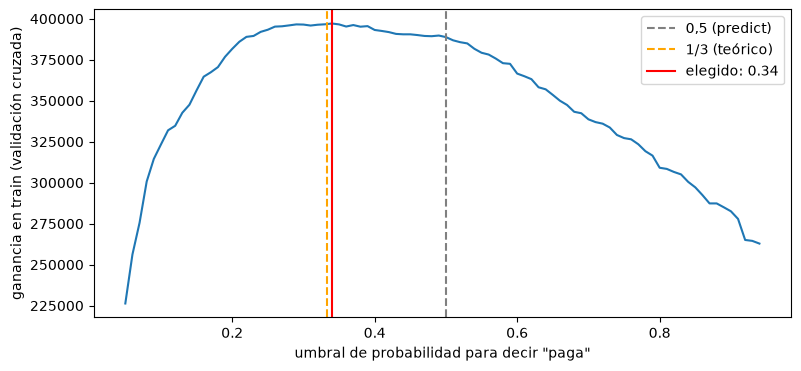

Umbral elegido: 0.34
Árbol base                      159300
Árbol ajustado (umbral 0,5)     169650
Árbol ajustado (umbral 0.34)    170850
Referencia del enunciado        166000
Name: Ganancia en test (US$), dtype: int64


In [33]:
proba_oof = cross_val_predict(modelo_ajustado, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
umbrales = np.arange(0.05, 0.95, 0.01)
ganancias_umbral = [ganancia(y_train, proba_oof >= u) for u in umbrales]
umbral = float(umbrales[np.argmax(ganancias_umbral)])

plt.figure(figsize=(9, 4))
plt.plot(umbrales, ganancias_umbral)
plt.axvline(0.5, color='gray', linestyle='--', label='0,5 (predict)')
plt.axvline(1/3, color='orange', linestyle='--', label='1/3 (teórico)')
plt.axvline(umbral, color='red', label=f'elegido: {umbral:.2f}')
plt.xlabel('umbral de probabilidad para decir "paga"')
plt.ylabel('ganancia en train (validación cruzada)')
plt.legend()
plt.show()

ganancia_umbral_test = ganancia(y_test, modelo_ajustado.predict_proba(X_test)[:, 1] >= umbral)
print(f"Umbral elegido: {umbral:.2f}")
print(pd.Series({
    'Árbol base': ganancia_base_test,
    'Árbol ajustado (umbral 0,5)': ganancia_ajustada_test,
    f'Árbol ajustado (umbral {umbral:.2f})': ganancia_umbral_test,
    'Referencia del enunciado': 166_000,
}, name='Ganancia en test (US$)'))

assert len(proba_oof) == len(X_train)   # el umbral NO se eligió con test
assert 0 < umbral < 1

**Resultado:** el mejor umbral en validación cruzada es **0,34**, muy cerca del 1/3 teórico. En test la ganancia pasa de US$ 169.650 (umbral 0,5) a **US$ 170.850**, por encima de la referencia del enunciado.

| Modelo | Ganancia en test |
|---|---|
| Árbol base | US$ 159.300 |
| Árbol ajustado (umbral 0,5) | US$ 169.650 |
| Árbol ajustado (umbral 0,34) | US$ 170.850 |
| Referencia del enunciado | ~US$ 166.000 |

Limitaciones:
- La curva es escalonada: con hojas de al menos 50 casas, las probabilidades toman pocos valores. Por eso 0,34 es el borde de un tramo plano, no un valor exacto.
- Los hiperparámetros se eligieron con umbral 0,5 y el umbral después, con las mismas particiones. Eso hace la estimación levemente optimista, y puede que otra combinación de hiperparámetros rinda más con su propio umbral.


## ¿Qué aprendió el árbol?

**Qué hace:** muestra la importancia de cada variable (cuánto reduce la impureza en total cada una; suman 1) y los primeros 3 niveles del árbol ajustado.

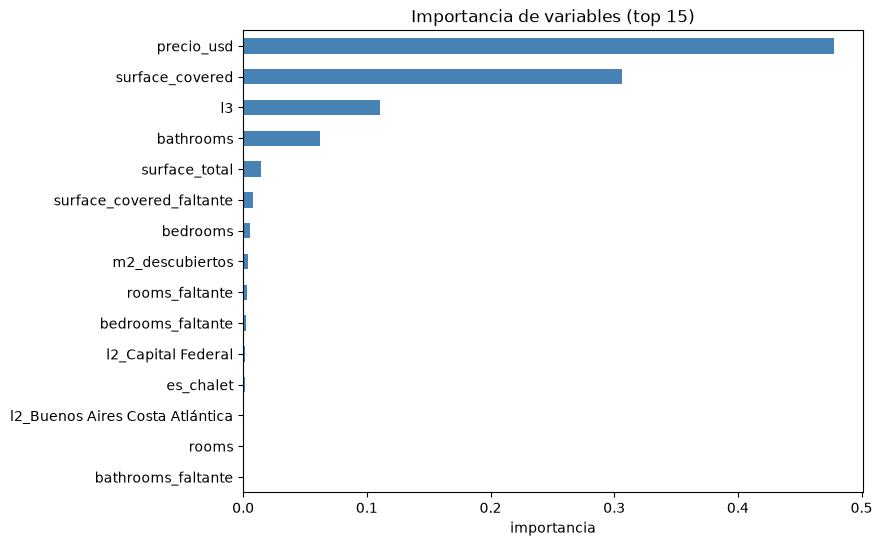

In [34]:
arbol = modelo_ajustado[-1]
importancias = pd.Series(arbol.feature_importances_, index=arbol.feature_names_in_).sort_values(ascending=False)
assert abs(importancias.sum() - 1) < 1e-9

plt.figure(figsize=(8, 6))
importancias.head(15).sort_values().plot.barh(color='steelblue')
plt.title('Importancia de variables (top 15)')
plt.xlabel('importancia')
plt.show()

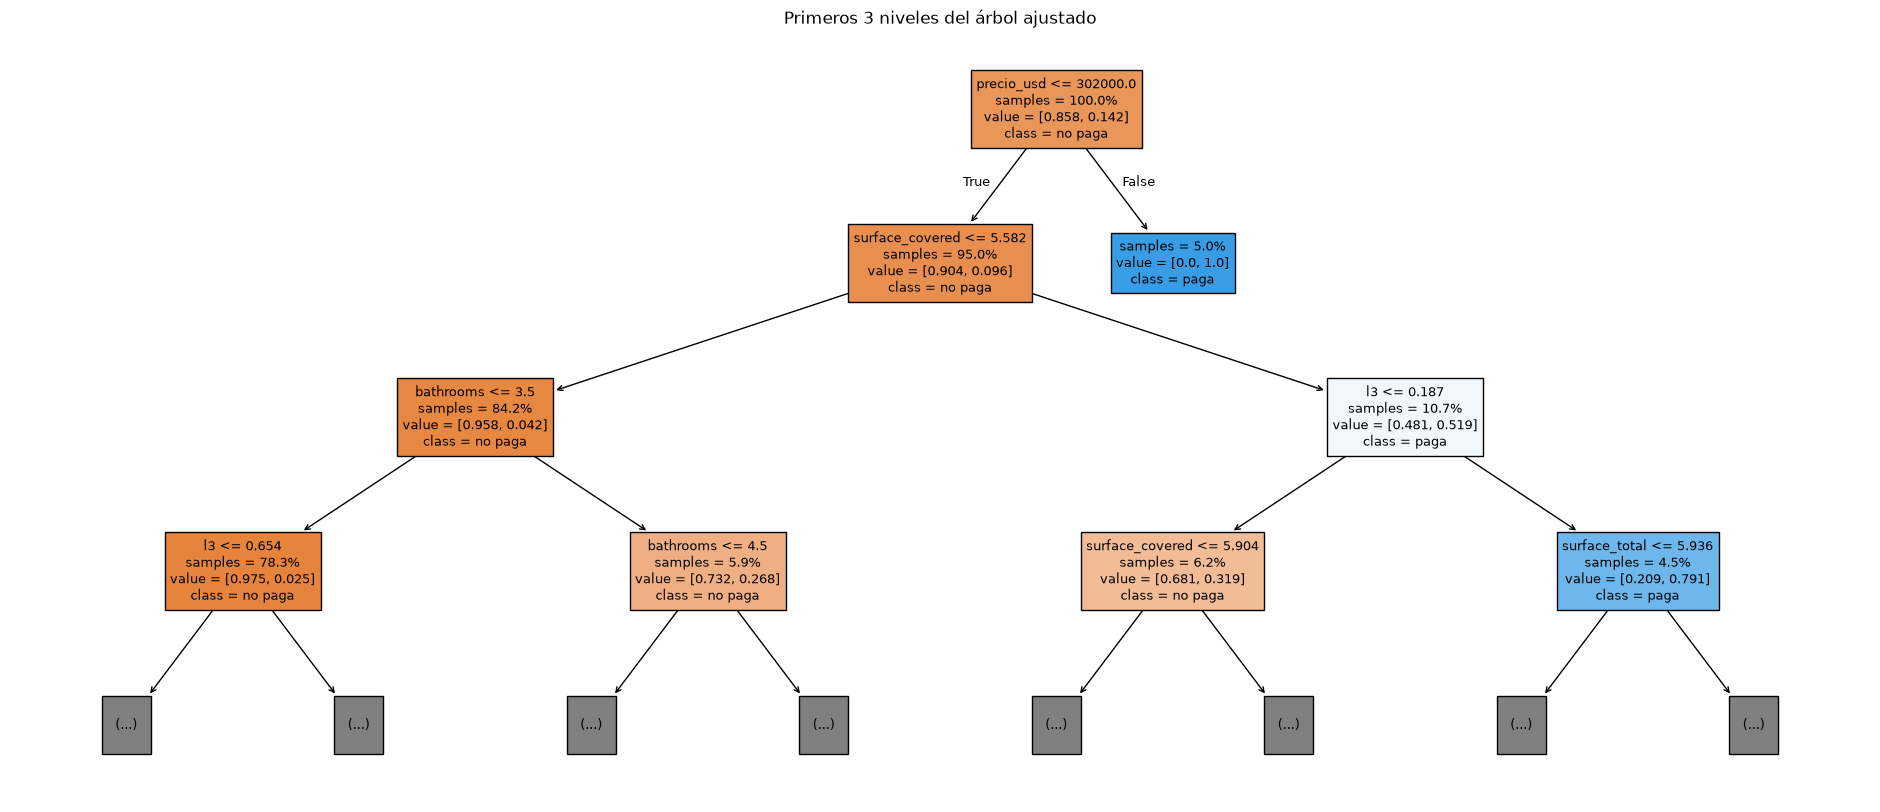

In [35]:
plt.figure(figsize=(24, 10))
plot_tree(arbol, max_depth=3, feature_names=list(arbol.feature_names_in_), class_names=['no paga', 'paga'],
          filled=True, proportion=True, impurity=False, fontsize=9)
plt.title('Primeros 3 niveles del árbol ajustado')
plt.show()

**Qué aprendió:** las cuatro variables más importantes son `precio_usd` (48%), `surface_covered` (31%), `l3` (la tasa de pago de la ciudad, 11%) y `bathrooms` (6%). Coincide con el análisis exploratorio: precio, tamaño y ubicación son lo que separa a las casas que pagan.

Los primeros cortes del árbol:
1. **Precio del título**: el primer corte es en `precio_usd` ≈ **US$ 302.000**, prácticamente la regla del enunciado (después de corregir las etiquetas, toda casa con precio > US$ 300.000 es `paga`). Las casas de más de ese precio caen directo en una hoja `paga`; las que no tienen precio en el título van del lado de las baratas.
2. **Casas sin precio o de hasta US$ 302.000**: el siguiente corte es `surface_covered` ≈ 5,58, que en m² es unos **265 m²** (la variable está en escala log).
3. **Debajo de ese corte**: las casas chicas se separan por `bathrooms` (3,5) y las grandes por la tasa de pago de la ciudad (`l3` codificada), en 0,187.

Las banderas sacadas del título (dúplex, PH, piscina, country, etc.) casi no se usan: solo `es_chalet` aparece entre las 15 más importantes, con 0,2%.

## Entregable

**Qué hace:** reentrena el árbol con **todo** el entrenamiento (train + test) usando los hiperparámetros y el umbral elegidos, predice `casas_predecir` y guarda en `casas_entrega.csv` los ids de las casas que predice `paga`. Al final verifica lo que pide el enunciado: que los ids sean de `casas_predecir` y ninguno de entrenamiento.

In [36]:
modelo_final = clone(modelo_ajustado).fit(X, y)
proba_predecir = modelo_final.predict_proba(X_predecir)[:, 1]
ids_paga = X_predecir.index[proba_predecir >= umbral]
pd.DataFrame(index=ids_paga).to_csv('casas_entrega.csv', index_label='id')

pct_test = (modelo_ajustado.predict_proba(X_test)[:, 1] >= umbral).mean() * 100
print(f"Casas predichas 'paga': {len(ids_paga)} de {len(X_predecir)} ({len(ids_paga) / len(X_predecir):.1%})")
print(f"En test el modelo predijo 'paga' en el {pct_test:.1f}% de las casas")

assert len(proba_predecir) == len(df_casas_predecir) == 41054
assert ids_paga.isin(df_casas_predecir['id']).all()             # ids de predecir
assert not ids_paga.isin(df_casas_entrenamiento['id']).any()    # ninguno de entrenamiento
assert ids_paga.is_unique and len(ids_paga) > 0
releido = pd.read_csv('casas_entrega.csv')
assert list(releido.columns) == ['id'] and len(releido) == len(ids_paga)

Casas predichas 'paga': 6251 de 41054 (15.2%)
En test el modelo predijo 'paga' en el 14.6% de las casas


**Nota sobre la regla de US$ 300.000:** antes de corregir las etiquetas, la mejor ganancia del árbol en test era de US$ 111.000, baja para lo que pide el enunciado. La causa era que `paga_comision` en `casas_entrenamiento.csv` no seguía esa regla: había casas con precio en el título por encima de US$ 300.000 marcadas como `no paga`, y el modelo aprendía de esas etiquetas.

Con la corrección del paso *Trampas de estructura (4/4)* (1.856 etiquetas pasadas a `paga`), el árbol ajustado llega a US$ 170.850 en test y su primer corte pasa a ser justamente el precio, en ~US$ 302.000.

# Modelado: Random Forest
Entrenamos un `RandomForestClassifier` ([documentación](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)) encadenado al **mismo pipeline de preprocesamiento** que el árbol, con la misma separación train/test, la misma validación cruzada y la misma función de ganancia. Así la comparación con el árbol es justa.

**Por qué un bosque:** el árbol solo sobreajusta (sin límites memoriza grupitos de casas) y sus probabilidades toman pocos valores. Un bosque promedia cientos de árboles, cada uno entrenado con una muestra distinta de casas (*bootstrap*) y mirando un subconjunto de variables en cada corte (`max_features`). El promedio reduce la varianza y da probabilidades más finas, lo que además ayuda a elegir el umbral.


## Ajuste de hiperparámetros

- `max_depth` y `min_samples_leaf`: cuánto puede crecer cada árbol del bosque.
- `max_features`: cuántas variables mira cada corte (`sqrt` ≈ 7 de 48, o el 30% / 50%). Menos variables = árboles más distintos entre sí.
- `class_weight='balanced_subsample'`: más peso a las `paga`, recalculado en cada muestra bootstrap.

**Qué hace:** la grilla completa tiene 150 combinaciones y cada bosque tarda bastante más que un árbol, así que en lugar de `GridSearchCV` usamos `RandomizedSearchCV`, que prueba **20 combinaciones al azar**, con validación cruzada de 5 partes sobre train y puntuando con la ganancia. Durante la búsqueda se fijan 300 árboles: más árboles casi nunca empeoran el bosque, solo lo hacen más lento.

In [37]:
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

# precio_usd llega con NaN: RandomForestClassifier los acepta desde scikit-learn 1.4
assert tuple(int(p) for p in sklearn.__version__.split('.')[:2]) >= (1, 4), "Se necesita scikit-learn >= 1.4"

pipeline_rf = Pipeline([
    ('preprocesamiento', clone(preprocesamiento)),
    # n_jobs=1 en el bosque: la paralelización la hace la búsqueda (una combinación por núcleo)
    ('modelo', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=1)),
])
param_dist_rf = {
    'modelo__max_depth': [10, 15, 20, 30, None],
    'modelo__min_samples_leaf': [1, 2, 5, 10, 20],
    'modelo__max_features': ['sqrt', 0.3, 0.5],
    'modelo__class_weight': [None, 'balanced_subsample'],
}
busqueda_rf = RandomizedSearchCV(pipeline_rf, param_dist_rf, n_iter=20, scoring=scorer_ganancia,
                                 cv=cv, n_jobs=-1, random_state=42)
busqueda_rf.fit(X_train, y_train)

resultados_rf = pd.DataFrame(busqueda_rf.cv_results_)
columnas_rf = [f'param_{p}' for p in param_dist_rf] + ['mean_test_score', 'std_test_score']
display(resultados_rf.sort_values('rank_test_score')[columnas_rf].head(10))
print("Mejores hiperparámetros:", busqueda_rf.best_params_)

,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__max_features,param_modelo__class_weight,mean_test_score,std_test_score
7,None,2,0.3,balanced_subsample,84220.0,694.694177
10,20,1,0.3,balanced_subsample,84030.0,1137.804904
19,30,5,0.5,balanced_subsample,82770.0,798.498591
12,20,2,0.3,NaN,81860.0,792.085854
18,30,1,0.5,NaN,81760.0,682.202316
15,30,2,0.5,NaN,81470.0,408.166633
2,20,10,0.5,balanced_subsample,80590.0,1396.209153
5,20,2,sqrt,NaN,80170.0,647.765390
0,None,10,0.5,NaN,80150.0,983.361582
11,10,5,0.5,NaN,79490.0,1043.743263


Mejores hiperparámetros: {'modelo__min_samples_leaf': 2, 'modelo__max_features': 0.3, 'modelo__max_depth': None, 'modelo__class_weight': 'balanced_subsample'}


In [38]:
modelo_rf = busqueda_rf.best_estimator_   # ya reentrenado con todo X_train
ganancia_rf_train = ganancia(y_train, modelo_rf.predict(X_train))
ganancia_rf_test = ganancia(y_test, modelo_rf.predict(X_test))
print(f"Ganancia train: US$ {ganancia_rf_train:,} | test: US$ {ganancia_rf_test:,}")

assert busqueda_rf.n_splits_ == 5
assert ganancia_rf_test > 0

Ganancia train: US$ 520,250 | test: US$ 183,350


## Umbral de decisión

Igual que con el árbol: con +100 / −50 conviene decir `paga` cuando la probabilidad supera ~1/3, no 0,5. El umbral se elige con las probabilidades *out-of-fold* de train (`cross_val_predict`); el test no participa.

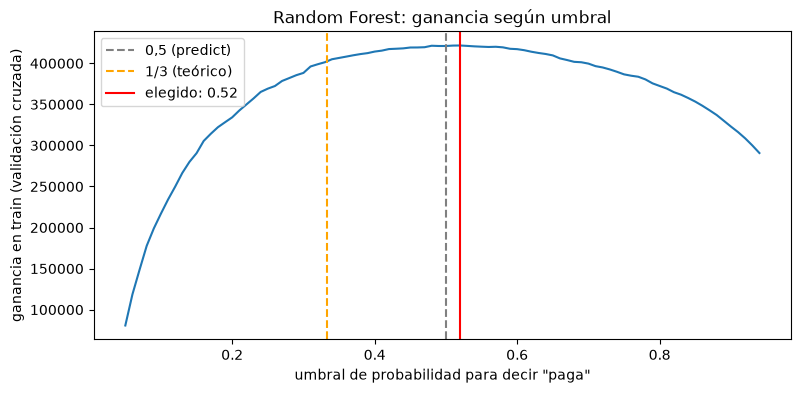

Umbral elegido: 0.52
Test: 17996 casas, 2547 pagan | VP: 2073 | FP: 479 | FN: 474
Random Forest (umbral 0,5)     183350
Random Forest (umbral 0.52)    183350
Máximo posible en test         254700
Referencia del enunciado       166000
Name: Ganancia en test (US$), dtype: int64


In [39]:
proba_oof_rf = cross_val_predict(modelo_rf, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
umbrales_rf = np.arange(0.05, 0.95, 0.01)
ganancias_umbral_rf = [ganancia(y_train, proba_oof_rf >= u) for u in umbrales_rf]
umbral_rf = float(umbrales_rf[np.argmax(ganancias_umbral_rf)])

plt.figure(figsize=(9, 4))
plt.plot(umbrales_rf, ganancias_umbral_rf)
plt.axvline(0.5, color='gray', linestyle='--', label='0,5 (predict)')
plt.axvline(1/3, color='orange', linestyle='--', label='1/3 (teórico)')
plt.axvline(umbral_rf, color='red', label=f'elegido: {umbral_rf:.2f}')
plt.xlabel('umbral de probabilidad para decir "paga"')
plt.ylabel('ganancia en train (validación cruzada)')
plt.title('Random Forest: ganancia según umbral')
plt.legend()
plt.show()

pred_rf = modelo_rf.predict_proba(X_test)[:, 1] >= umbral_rf
ganancia_rf_umbral_test = ganancia(y_test, pred_rf)
vp_rf = int((pred_rf & (y_test == 1)).sum())
fp_rf = int((pred_rf & (y_test == 0)).sum())
fn_rf = int((~pred_rf & (y_test == 1)).sum())
print(f"Umbral elegido: {umbral_rf:.2f}")
print(f"Test: {len(X_test)} casas, {int(y_test.sum())} pagan | VP: {vp_rf} | FP: {fp_rf} | FN: {fn_rf}")
print(pd.Series({
    'Random Forest (umbral 0,5)': ganancia_rf_test,
    f'Random Forest (umbral {umbral_rf:.2f})': ganancia_rf_umbral_test,
    'Máximo posible en test': 100 * int(y_test.sum()),
    'Referencia del enunciado': 166_000,
}, name='Ganancia en test (US$)'))

assert len(proba_oof_rf) == len(X_train)   # el umbral NO se eligió con test
assert vp_rf + fn_rf == y_test.sum()

## ¿Qué variables usa el bosque?

Importancia promedio de cada variable en los 300 árboles (reducción total de impureza; suman 1).

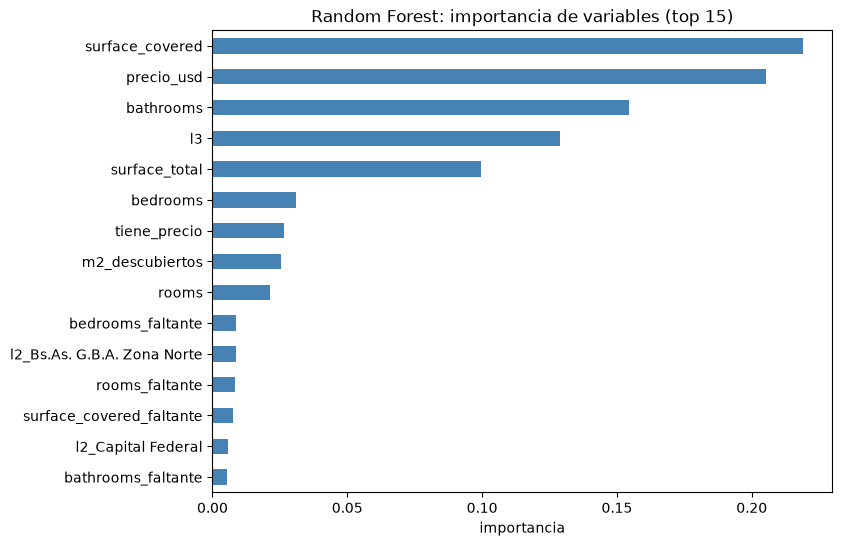

surface_covered      0.219
precio_usd           0.205
bathrooms            0.155
l3                   0.129
surface_total        0.100
bedrooms             0.031
tiene_precio         0.026
m2_descubiertos      0.026
rooms                0.021
bedrooms_faltante    0.009
dtype: float64


In [40]:
bosque = modelo_rf[-1]
importancias_rf = pd.Series(bosque.feature_importances_, index=bosque.feature_names_in_).sort_values(ascending=False)
assert abs(importancias_rf.sum() - 1) < 1e-9

plt.figure(figsize=(8, 6))
importancias_rf.head(15).sort_values().plot.barh(color='steelblue')
plt.title('Random Forest: importancia de variables (top 15)')
plt.xlabel('importancia')
plt.show()
print(importancias_rf.head(10).round(3))

## Entregable (Random Forest)

**Qué hace:** reentrena el bosque con **todo** el entrenamiento (train + test) usando los hiperparámetros y el umbral elegidos, predice `casas_predecir` y guarda los ids que predice `paga` en `casas_entrega_random_forest.csv` (archivo aparte, para no pisar el entregable del árbol). Verifica que los ids sean de `casas_predecir` y ninguno de entrenamiento.

In [41]:
modelo_rf_final = clone(modelo_rf).set_params(modelo__n_jobs=-1).fit(X, y)
proba_predecir_rf = modelo_rf_final.predict_proba(X_predecir)[:, 1]
ids_paga_rf = X_predecir.index[proba_predecir_rf >= umbral_rf]
pd.DataFrame(index=ids_paga_rf).to_csv('casas_entrega_random_forest.csv', index_label='id')

pct_test_rf = pred_rf.mean() * 100
print(f"Casas predichas 'paga': {len(ids_paga_rf)} de {len(X_predecir)} ({len(ids_paga_rf) / len(X_predecir):.1%})")
print(f"En test el modelo predijo 'paga' en el {pct_test_rf:.1f}% de las casas")

assert len(proba_predecir_rf) == len(df_casas_predecir) == 41054
assert ids_paga_rf.isin(df_casas_predecir['id']).all()             # ids de predecir
assert not ids_paga_rf.isin(df_casas_entrenamiento['id']).any()    # ninguno de entrenamiento
assert ids_paga_rf.is_unique and len(ids_paga_rf) > 0
releido_rf = pd.read_csv('casas_entrega_random_forest.csv')
assert list(releido_rf.columns) == ['id'] and len(releido_rf) == len(ids_paga_rf)

Casas predichas 'paga': 5854 de 41054 (14.3%)
En test el modelo predijo 'paga' en el 14.2% de las casas


**Resultado:** la búsqueda eligió `max_depth=None`, `min_samples_leaf=2`, `max_features=0.3` y `class_weight='balanced_subsample'`. Ese mejor bosque quedó con un umbral de **0,52** y una ganancia en test de **US$ 183.350** (2.073 aciertos y 479 falsos positivos sobre 2.547 casas que pagan).

| Modelo | Ganancia en test |
|---|---|
| Árbol ajustado (umbral 0,34) | US$ 170.850 |
| Random Forest (umbral 0,5) | US$ 183.350 |
| Random Forest (umbral 0,52) | US$ 183.350 |
| Máximo posible | US$ 254.700 |
| Referencia del enunciado | ~US$ 166.000 |

- El bosque le gana al árbol por unos **US$ 12.500** en test con el mismo preprocesamiento y el mismo split.
- A diferencia del árbol, acá sí gana `class_weight='balanced_subsample'`. Por eso el umbral óptimo queda cerca de 0,5 y no de 1/3: el peso extra a las `paga` ya corre las probabilidades hacia arriba. Entre 0,5 y 0,52 no hay diferencia en test.
- Train (US$ 520.250) sigue muy por encima de test: con `min_samples_leaf=2` cada árbol memoriza bastante, pero el promedio de 300 árboles generaliza mejor que un árbol solo.
- Las variables más importantes siguen siendo tamaño, precio y ubicación: `surface_covered` (22%), `precio_usd` (20%), `bathrooms` (15%), `l3` (13%) y `surface_total` (10%).
- El modelo final predice `paga` en 5.854 de las 41.054 casas de `casas_predecir` (14,3%), una proporción parecida a la del test (14,2%).

El bosque supera la referencia del enunciado por unos US$ 17.000. Para seguir mejorando se puede probar boosting (`HistGradientBoostingClassifier`, XGBoost, LightGBM).